# 03_reproduction_completion.ipynb — Reproduction completion: published comparison, outlier resamples, Rocket family, ablations

**Author:** Shreed. **Notebook:** `01_reproduction/notebooks/03_reproduction_completion.ipynb`. COMP41850 HYDRA team project, reproduction section.

This notebook completes four open reproduction tasks for *HYDRA: Competing convolutional kernels for fast and accurate time series classification* (Dempster, Schmidt & Webb). Each part runs on its own and is switched on or off with a flag.

| Part | What | New model runs? |
|---|---|---|
| **C** | Our 112-dataset Hydra baseline and the authors' results against published results (HC2, TDE, MrSQM, InceptionTime, ROCKET, …) | none (downloads published CSVs) |
| **D** | 30 resamples of Hydra on the 18 outlier datasets, a normalisation scan, and an EOG z-normalisation diagnostic | Hydra only |
| **B** | MiniRocket, MultiRocket, Hydra, Hydra+MultiRocket (and Hydra+MiniRocket) on all 112 datasets, default split | yes |
| **A** | Hydra ablations on the 40 development datasets: counting, differencing, clipping, k/g sweep from k = 1 to k = 512 | yes |

Every model in this notebook uses the **authors' ridge grid `np.logspace(-3, 3, 10)`**, and records the chosen alpha and whether it is at the edge of the grid.

## Claim labels used in this notebook

| Label | Paper claim | Evidence here |
|---|---|---|
| C1 | Hydra is more accurate than the dictionary methods TDE and MrSQM | Part C (a) |
| C2 | Hydra is close to ROCKET, InceptionTime and TS-CHIEF, and below HC2 | Part C (a) |
| C3 | Adding Hydra to MultiRocket (Hydra+MultiRocket) improves on both | Part B, Part C |
| C4 | Design choices: k = 8 is a good default; max+min, soft+hard counting, first-order differencing and (at k = 1) clipping help | Part A |
| C5 | The published per-dataset accuracies are reproducible (within resampling noise) | Part D, Part C (b) |

The final cell maps these labels to the numbers each part produced. It prints numbers only.

## Run guide

**Order:** run **C → D → B → A** (cheapest and most informative first). Each part checkpoints after every unit and resumes on restart, so a crash or a stop loses at most one unit.

**Flags** (settings cell):

| Flag | Default | Meaning |
|---|---|---|
| `QUICK_RUN` | `True` | tiny smoke test of every enabled part (2–3 small datasets, 1–2 seeds/resamples); all outputs get a `quick_` prefix |
| `RUN_CHECKS` | `True` | pre-experiment equivalence checks (seconds) |
| `RUN_PART_C` / `RUN_PART_D` / `RUN_PART_B` / `RUN_PART_A` | `True` | run that part (its analysis cells only run if its CSV exists) |
| `INCLUDE_H_MINI` | `True` | also fit Hydra+MiniRocket in Part B (cheap: the features are already computed) |
| `INCLUDE_SOFT_ONLY_MAHAK` | `True` | also fit Mahak's exact soft-min variant in Part A |
| `N_SEEDS` | 5 | Part A kernel seeds (0 … N_SEEDS−1) |

**Set `QUICK_RUN = False` for the real run.** Suggested sequence: one quick run of everything (a few minutes) → `QUICK_RUN = False` with only `RUN_PART_C = True` → then D, then B, then A (or several parts in one overnight run).

**Rough times on the Mac (10 cores, 16 GB):** C minutes · D ≈ 1–1.5 h · B ≈ 1.5–3 h · A ≈ 3–5 h (5 seeds).

**Outputs** (all in `01_reproduction/results/`, figures in `01_reproduction/results/figures/`; prefix `quick_` when `QUICK_RUN = True`):

| Part | Files |
|---|---|
| all | `repro_failures.csv` (one row per failed unit; never substituted) |
| C | `repro_partC_published.csv` (long format), `repro_partC_claims.csv`, `repro_partC_ours_vs_published_r0.csv`, `repro_partC_ranks.csv`, `repro_partC_outliers.csv`, figures `repro_partC_*.png` |
| D | `repro_partD_resamples.csv`, `repro_partD_normalisation_scan.csv`, `repro_partD_summary.csv`, figures `repro_partD_*.png` |
| B | `repro_partB_rocket112.csv`, `repro_partB_pairs.csv`, figures `repro_partB_*.png` |
| A | `repro_partA_ablations.csv`, `repro_partA_*.csv` tables, figures `repro_partA_*.png` |
| summary | `repro_claims_summary.csv` |

**Headless run** (from the project root; `caffeinate -i` stops the Mac sleeping):

```bash
nohup caffeinate -i jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=-1 01_reproduction/notebooks/03_reproduction_completion.ipynb \
  > 01_reproduction/results/repro_log.txt 2>&1 &
```

The headless command needs `nbconvert` and `ipykernel` in the Python environment that has the packages from `requirements.txt` (`pip install nbconvert ipykernel`). If Jupyter runs from a different environment, register this one as a kernel once (`python -m ipykernel install --user --name <name>`) and add `--ExecutePreprocessor.kernel_name=<name>`. Running the cells in VS Code / Jupyter with that interpreter also works.

**Memory:** the largest Part B units (ElectricDevices, Crop: ~54k features, 7–9k training cases) need roughly 10–12 GB at the ridge fit. Close other large applications before Part B. If one unit runs out of memory it is logged in `repro_failures.csv` and the part continues.

## Step 0: what the source code says (read before writing this notebook)

**aeon's own Rocket classifiers (aeon 1.6.0).** `MiniRocketClassifier._fit` and `MultiRocketClassifier._fit` build `make_pipeline(transformer, StandardScaler(with_mean=False), RidgeClassifierCV(alphas=np.logspace(-3, 3, 10)))`. `MultiRocketHydraClassifier._fit` scales the Hydra block with `_SparseScaler()` and the MultiRocket block with `StandardScaler()` (with centring), then concatenates and fits `RidgeClassifierCV(np.logspace(-3, 3, 10))`. Both MiniRocket and MultiRocket transformers cast the input to float32 internally (`X = X.astype(np.float32)`).

- **Consequence for Part B.** Standalone MiniRocket and MultiRocket use a `StandardScaler` like aeon's. `RidgeClassifierCV` fits an intercept, so it centres every column itself; dividing by the column standard deviation with or without centring first gives the same ridge solution. Part B therefore uses one scaled MultiRocket block (Aarti's `StandardScaler()`) for both standalone MultiRocket and the combination, so *Hydra+MultiRocket vs MultiRocket differs only by the Hydra block*. A check on the first datasets fits the aeon variant (`with_mean=False`) as well and prints how many predictions differ.
- **Deviation from Aarti's notebook.** Her standalone MiniRocket and MultiRocket fed **raw** features to the ridge; only her combination scaled them. Here standalone models are scaled as in aeon's classifiers (above).

**`aeon.benchmarking.results_loaders`.**
- `get_available_estimators(task="classification", as_list=False)` reads `https://timeseriesclassification.com/results/ReferenceResults/classification/estimators.txt`.
- `get_estimator_results(estimators, datasets=None, num_resamples=1, task="classification", measure="accuracy", remove_dataset_modifiers=False, path="https://timeseriesclassification.com/results/ReferenceResults")` reads `{path}/classification/accuracy/{Name}_accuracy.csv` (one row per dataset, first column the dataset, then one column per resample). **`num_resamples=1` returns the score of resample 0, which is the default train/test split**; an integer n ≥ 2 returns the first n resamples; `None` returns all resamples. It raises `ValueError` if a requested dataset has a missing resample.
- `get_estimator_results_as_array(...)` returns a datasets × estimators array, **averaged** over the requested resamples.
- `estimator_alias(name)` maps aliases to the file names via `NAME_ALIASES`: for example `MultiROCKET → MR`, `MultiROCKET-Hydra → MR-Hydra`, `HIVECOTEV2 → HC2`.
- Part C requests resample 0 with `num_resamples=1` and all resamples with `num_resamples=None`, checks that the first column of the latter equals the former, and averages the first 30 resamples itself.

**Mahak's soft-min (`HydraCountingVariant`, cell 13 of `02_hydra_ablation.ipynb`).** With `min_counting="soft"` it accumulates the **raw minimum values** (`min_updates = min_values`), which are almost always negative. `SparseScaler` computes `X.clamp(0).sqrt()` before standardising, so negative sums become 0 and those features are (almost) all zero after scaling: Mahak's `soft_only` is effectively soft-max only. Part A keeps her exact version as an extra variant, **`soft_only_mahak`**, and uses the magnitude **(−min)** for its own soft-min (the paper says counting the min is equivalent to counting the max with −W). Check A2 prints the fraction of `soft_only_mahak` min-columns that are non-zero after scaling.

**Official edge case.** `Hydra` sets `divisor = min(2, g)`. With g = 1 (k = 512) the divisor is 1, so the single group reads only the raw series and there is no first-order-difference group. This matches the official code and the paper's single-group configuration; Part A keeps it.

## Setup

In [1]:
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"        # official hydra.py
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"     # published results CSVs
DATA_DIR    = ROOT / "data" / "ucr_tsml"                  # local UCR cache (git-ignored)
RESULTS_DIR = ROOT / "01_reproduction" / "results"
FIG_DIR     = RESULTS_DIR / "figures"                     # use the figures folder that exists, or create this one
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

# Names used in the rest of this notebook
PROJECT_DIR = ROOT
REPO_DIR = ROOT / "hydra-authors-repo"
BASELINE_CSV = RESULTS_DIR / "hydra_default_baseline.csv"     # read only (written by 01_hydra_baseline.ipynb)
print("Project directory:", PROJECT_DIR.resolve())
AUTHORS_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"            # read only
AUTHORS_VARIANTS_CSV = AUTHORS_RES / "results_ucr112_variants.csv"  # read only
PUBLISHED_LOCAL_DIR = ROOT / "data" / "published_results"           # optional fallback for Part C

Project directory: /Users/shreed/PROJECTS/Hydra_1


In [2]:
import gc
import importlib.util
import inspect
import json
import math
import os
import sys
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats as sstats
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from aeon.transformations.collection.convolution_based import MiniRocket, MultiRocket
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

# Ridge at small alpha with n_train << n_features gives a near-singular Gram matrix; sklearn warns and
# falls back to a least-squares solve. These are warnings, not errors - results are still computed.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")
warnings.filterwarnings("ignore", message="The least populated class")

import aeon, sklearn
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__,
      "| aeon", aeon.__version__, "| sklearn", sklearn.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0 | aeon 1.6.0 | sklearn 1.9.1


### Settings

**Set `QUICK_RUN = False` for the real run.** With `QUICK_RUN = True` every enabled part runs on a tiny subset and writes `quick_*` files, so the real result files are never touched by a smoke test.

In [3]:
# ===================== settings =====================
QUICK_RUN = False            # True: tiny smoke test, writes quick_* files. Set False for the real run.
RUN_CHECKS = True           # pre-experiment equivalence checks (seconds)
RUN_PART_C = True           # published-results comparison (downloads only)
RUN_PART_D = True           # 30 resamples on the 18 outliers + normalisation scan + EOG diagnostic
RUN_PART_B = True           # MiniRocket / MultiRocket / Hydra / Hydra+MultiRocket on 112 datasets
RUN_PART_A = True           # ablations on the 40 development datasets
INCLUDE_H_MINI = True       # Part B: also Hydra+MiniRocket
INCLUDE_SOFT_ONLY_MAHAK = True  # Part A: also Mahak's exact soft-min variant
N_SEEDS = 5                 # Part A kernel seeds 0..N_SEEDS-1 (the paper averages 10 runs)

AUTHOR_ALPHAS = np.logspace(-3, 3, 10)     # the authors' ridge grid, used by EVERY model in this notebook
N_BOOT = 10_000                            # bootstrap resamples for CIs (seed 0)
DRAW_TOL = 0.0005                          # |delta| <= 0.05 pp counts as a draw
BATCH_SIZE = 256
N_THREADS = os.cpu_count()
torch.set_num_threads(N_THREADS)
N_JOBS = N_THREADS                         # aeon transforms: all threads
RANDOM_STATE = 42                          # Aarti's MiniRocket / MultiRocket random_state (unchanged)
HYDRA_SEED_B = 0                           # Part B Hydra seed: 0, so standalone Hydra = 01_hydra_baseline.ipynb
TEST_CHUNK = 2048                          # Part B: rocket test features are computed and predicted in chunks

# ---- dataset lists ----
UCR112 = pd.read_csv(AUTHORS_CSV)["dataset"].astype(str).str.strip().tolist()
assert len(UCR112) == 112 and len(set(UCR112)) == 112

# The 40 "development" datasets (asterisked in ROCKET, arXiv 1910.13051, Appendix D, Table 1),
# as extracted by the team. Not re-verified against the PDF in this notebook - see the findings caveats.
DEV_DATASETS = [
    "Beef", "BirdChicken", "Car", "CricketX", "CricketY", "CricketZ", "DistalPhalanxTW", "ECG5000",
    "FiftyWords", "Fish", "FordA", "FordB", "Haptics", "Herring", "InsectWingbeatSound",
    "ItalyPowerDemand", "LargeKitchenAppliances", "Lightning7", "Meat", "MedicalImages",
    "MiddlePhalanxOutlineAgeGroup", "MiddlePhalanxOutlineCorrect", "OSULeaf", "OliveOil", "Phoneme",
    "Plane", "ProximalPhalanxOutlineCorrect", "ProximalPhalanxTW", "ScreenType", "ShapeletSim",
    "Strawberry", "SwedishLeaf", "SyntheticControl", "ToeSegmentation1", "Trace",
    "UWaveGestureLibraryY", "Wafer", "WordSynonyms", "Worms", "Yoga",
]
assert len(DEV_DATASETS) == 40 and len(set(DEV_DATASETS)) == 40, "need 40 unique development datasets"
assert set(DEV_DATASETS) <= set(UCR112)

EXPECTED_OUTLIERS = [
    "EOGVerticalSignal", "EOGHorizontalSignal", "RefrigerationDevices", "ScreenType", "ElectricDevices",
    "Computers", "FordB", "Ham", "FaceAll", "LargeKitchenAppliances", "EthanolLevel", "Meat",
    "MiddlePhalanxOutlineAgeGroup", "BeetleFly", "DistalPhalanxOutlineAgeGroup", "ACSF1", "PigCVP", "Herring",
]

# 01_hydra_baseline.ipynb baseline (seed 0, default split, authors' grid): accuracy and the size used to order datasets
NB1 = pd.read_csv(BASELINE_CSV)
assert len(NB1) == 112 and set(NB1["dataset"]) == set(UCR112), "Notebook 1 baseline must cover the 112 datasets"
assert (NB1["seed"] == 0).all() and (NB1["k"] == 8).all() and (NB1["g"] == 64).all()
NB1 = NB1.set_index("dataset")
COST = NB1["n_train"] * NB1["series_length"]          # n_train x length, used to order units cheap -> expensive

def by_cost(names):
    return sorted(names, key=lambda d: (COST[d], d))

# ---- part settings ----
PARTC_ESTIMATORS = ["HC2", "TDE", "MrSQM", "InceptionTime", "ROCKET", "MiniROCKET", "MultiROCKET",
                    "DrCIF", "TS-CHIEF", "Hydra", "MultiROCKET-Hydra"]
PAPER_WDL = {"TDE": "73/2/37", "MrSQM": "69/1/42", "ROCKET": "56/3/53", "HC2": "27/5/80"}   # Hydra vs X, paper

if QUICK_RUN:
    D_DATASETS = ["BeetleFly", "Meat", "EOGVerticalSignal"]
    D_RESAMPLES = [0, 1]
    SCAN_DATASETS = D_DATASETS
    B_DATASETS = ["Coffee", "ECG200", "GunPoint"]
    A_DATASETS = ["ItalyPowerDemand", "Beef", "Plane"]
    A_SEEDS = [0, 1]
else:
    D_DATASETS = None                      # = the recomputed 18 outliers (Part D)
    D_RESAMPLES = list(range(30))
    SCAN_DATASETS = UCR112
    B_DATASETS = UCR112
    A_DATASETS = DEV_DATASETS
    A_SEEDS = list(range(N_SEEDS))
D_ZNORM_DATASETS = ["EOGVerticalSignal", "EOGHorizontalSignal"]
KG_KS = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]       # k x g = 512

# ---- outputs ----
TAG = "quick_" if QUICK_RUN else ""
def out(name):
    return RESULTS_DIR / f"{TAG}{name}"
def fig_path(name):
    return FIG_DIR / f"{TAG}{name}.png"
FAILURES_CSV = out("repro_failures.csv")
PARTC_CSV = out("repro_partC_published.csv")
PARTD_CSV = out("repro_partD_resamples.csv")
PARTD_SCAN_CSV = out("repro_partD_normalisation_scan.csv")
PARTB_CSV = out("repro_partB_rocket112.csv")
PARTA_CSV = out("repro_partA_ablations.csv")

print(f"QUICK_RUN={QUICK_RUN} | parts C={RUN_PART_C} D={RUN_PART_D} B={RUN_PART_B} A={RUN_PART_A} | threads {N_THREADS}")
print("outputs:", [p.name for p in [FAILURES_CSV, PARTC_CSV, PARTD_CSV, PARTD_SCAN_CSV, PARTB_CSV, PARTA_CSV]])

QUICK_RUN=False | parts C=True D=True B=True A=True | threads 10
outputs: ['repro_failures.csv', 'repro_partC_published.csv', 'repro_partD_resamples.csv', 'repro_partD_normalisation_scan.csv', 'repro_partB_rocket112.csv', 'repro_partA_ablations.csv']


In [4]:
# Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`). Not modified.
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler
print("official Hydra loaded from", HYDRA_SOURCE)

official Hydra loaded from /Users/shreed/PROJECTS/Hydra_1/hydra-authors-repo/code/hydra.py


### Shared building blocks

- **Copied unchanged from `shreed_detach_hydra_decisive.ipynb` (now `02_detach_hydra/notebooks/02_development_run.ipynb`):** the data loader (`load_ucr_dataset`, identical checks to `01_hydra_baseline.ipynb`), the stratified resampler `make_split`, `to_tensor`, and the helpers `alpha_at_edge`, `fit_ridge` (SparseScaler fitted on train only → `RidgeClassifierCV`), `append_csv`, `holm` and `compare` (bootstrap CI, W/D/L with draw tolerance 0.0005, two-sided Wilcoxon).
- **New:** CSV checkpoint helpers, failure logging, a progress/ETA printer, Hydra feature extraction with `01_hydra_baseline.ipynb`'s batching, and a pairwise-comparison table.

In [5]:
# ---- Data loading (same checks as 01_hydra_baseline.ipynb) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

In [6]:
# ---- copied unchanged from shreed_detach_hydra_decisive.ipynb ----

def alpha_at_edge(alpha, grid):
    return bool(np.isclose(alpha, grid[0]) or np.isclose(alpha, grid[-1]))

def fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid):
    # SparseScaler fitted on TRAIN ONLY; RidgeClassifierCV alpha chosen by LOO/GCV on TRAIN ONLY.
    sc = SparseScaler()
    A = sc.fit_transform(Ztr_raw).detach().cpu().numpy()
    B = sc.transform(Zte_raw).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=grid).fit(A, ytr)
    pred = clf.predict(B)
    return {"acc": accuracy_score(yte, pred), "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, grid), "n_features": int(A.shape[1])}

def append_csv(df, csv_path):
    df.to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)

def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(np.where(ok, p, np.inf))
    m, running = ok.sum(), 0.0
    for rank, i in enumerate(idx[:m]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out

def compare(a, b, seed=0):
    d = (a - b).dropna()
    dpp = d.to_numpy() * 100
    rng = np.random.default_rng(seed)
    boots = rng.choice(dpp, size=(N_BOOT, len(dpp)), replace=True).mean(axis=1) if len(dpp) > 1 else np.array([np.nan])
    try:
        p = wilcoxon(d.to_numpy(), zero_method="wilcox", alternative="two-sided").pvalue if (d.abs() > 0).any() else 1.0
    except ValueError:
        p = np.nan
    return {"mean_pp": dpp.mean(), "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
            "median_pp": np.median(dpp), "W": int((d > DRAW_TOL).sum()), "D": int((d.abs() <= DRAW_TOL).sum()),
            "L": int((d < -DRAW_TOL).sum()), "p": p, "n": len(d)}


# ---- new helpers ----
def csv_exists(path):
    return Path(path).exists()


def read_csv_safe(path):
    return pd.read_csv(path) if csv_exists(path) else pd.DataFrame()


def save_csv(df, path):
    df.to_csv(path, index=False)


def completed_units(path, keys):
    df = read_csv_safe(path)
    if df.empty:
        return set()
    return set(map(tuple, df[keys].astype(object).itertuples(index=False, name=None)))


def log_failure(part, unit, exc):
    row = pd.DataFrame([{"part": part, "unit": str(unit), "error_type": type(exc).__name__,
                         "error_message": str(exc)[:500],
                         "where": traceback.format_exc().strip().splitlines()[-3:][0][:300]}])
    append_csv(row, FAILURES_CSV)
    print(f"  FAILED {part} {unit}: {type(exc).__name__}: {str(exc)[:200]}")


class Progress:
    """Elapsed time and an ETA weighted by each unit's cost (n_train x length)."""
    def __init__(self, label, costs):
        self.label, self.costs = label, list(costs)
        self.total, self.done, self.n_done, self.t0 = float(sum(self.costs)), 0.0, 0, perf_counter()

    def step(self, cost, msg):
        self.done += cost
        self.n_done += 1
        el = perf_counter() - self.t0
        eta = el / self.done * (self.total - self.done) if self.done > 0 else float("nan")
        print(f"[{self.label} {el / 60:7.1f} min | ETA ~{eta / 60:6.1f} min] {self.n_done}/{len(self.costs)} {msg}", flush=True)


def hydra_features(model, X, batch_size=BATCH_SIZE):
    # same as 01_hydra_baseline.ipynb: inference mode, batches of 256, float32 tensor input
    with torch.inference_mode():
        return model.batch(to_tensor(X), batch_size=batch_size)


def znorm_series(X):
    # per-series z-normalisation (EOG diagnostic only)
    mu = X.mean(axis=-1, keepdims=True)
    sd = X.std(axis=-1, keepdims=True)
    return ((X - mu) / np.where(sd < 1e-8, 1.0, sd)).astype(np.float32)


def pair_table(pairs, label_a="a", label_b="b"):
    """pairs: list of (name, Series_a, Series_b) aligned by dataset. One row per pair, Holm over the list."""
    rows = []
    for name, a, b in pairs:
        both = pd.concat([a, b], axis=1, keys=["a", "b"]).dropna()
        r = compare(both["a"], both["b"])
        d = both["a"] - both["b"]
        rows.append({"comparison": name, "n": r["n"], f"mean_{label_a}": both["a"].mean(),
                     f"mean_{label_b}": both["b"].mean(), "mean_delta_pp": r["mean_pp"],
                     "ci_lo_pp": r["ci_lo"], "ci_hi_pp": r["ci_hi"], "median_delta_pp": r["median_pp"],
                     "W/D/L": f"{r['W']}/{r['D']}/{r['L']}",
                     "W/D/L_exact": f"{int((d > 0).sum())}/{int((d == 0).sum())}/{int((d < 0).sum())}",
                     "p": r["p"]})
    t = pd.DataFrame(rows)
    if len(t):
        t["p_holm"] = holm(t["p"].to_numpy())
    return t


CHECKS = []
def log_check(msg):
    CHECKS.append(msg)
    print("CHECK PASS:", msg)

### Outlier datasets (shared by Parts C and D)

An *outlier* is a dataset where our `01_hydra_baseline.ipynb` default-split accuracy differs from the authors' published 30-resample mean by more than 5 pp.

In [7]:
AUTH = pd.read_csv(AUTHORS_CSV).set_index("dataset")["accuracy"]
gap_pp = (NB1["accuracy"] - AUTH.reindex(NB1.index)) * 100
OUTLIERS = sorted(gap_pp.index[gap_pp.abs() > 5].tolist())
print(f"{len(OUTLIERS)} datasets with |ours - paper| > 5 pp")
outlier_table = pd.DataFrame({"ours_default_split": NB1["accuracy"].reindex(OUTLIERS),
                              "paper_30_mean": AUTH.reindex(OUTLIERS),
                              "gap_pp": gap_pp.reindex(OUTLIERS).round(2)}).sort_values("gap_pp")
display(outlier_table)
if set(OUTLIERS) != set(EXPECTED_OUTLIERS):
    print("Recomputed list differs from the expected list.")
    print("  recomputed:", OUTLIERS)
    print("  expected:  ", sorted(EXPECTED_OUTLIERS))
    print("  only recomputed:", sorted(set(OUTLIERS) - set(EXPECTED_OUTLIERS)),
          "| only expected:", sorted(set(EXPECTED_OUTLIERS) - set(OUTLIERS)))

18 datasets with |ours - paper| > 5 pp


,ours_default_split,paper_30_mean,gap_pp
dataset,,,
EOGVerticalSignal,0.494475,0.763996,-26.95
EOGHorizontalSignal,0.571823,0.826980,-25.52
RefrigerationDevices,0.506667,0.756089,-24.94
ScreenType,0.490667,0.624089,-13.34
ElectricDevices,0.753080,0.881671,-12.86
Computers,0.704000,0.818533,-11.45
FordB,0.824691,0.932181,-10.75
Ham,0.742857,0.847619,-10.48
FaceAll,0.898817,0.984300,-8.55


### Pre-experiment check: baseline sanity

ECG200 with seed 0 and the authors' grid must reproduce `01_hydra_baseline.ipynb` (0.8700). This also checks that `fit_ridge` with `AUTHOR_ALPHAS` is the `01_hydra_baseline.ipynb` pipeline.

In [8]:
if RUN_CHECKS:
    Xtr_, ytr_, Xte_, yte_ = load_ucr_dataset("ECG200")
    m_ = Hydra(Xtr_.shape[-1], k=8, g=64, seed=0)
    r_ = fit_ridge(hydra_features(m_, Xtr_), ytr_, hydra_features(m_, Xte_), yte_, AUTHOR_ALPHAS)
    assert abs(r_["acc"] - 0.87) < 1e-12 and abs(r_["acc"] - NB1.loc["ECG200", "accuracy"]) < 1e-12, r_
    log_check(f"ECG200 seed 0 with the authors' grid = {r_['acc']:.4f} (Notebook 1: {NB1.loc['ECG200', 'accuracy']:.4f})")

CHECK PASS: ECG200 seed 0 with the authors' grid = 0.8700 (Notebook 1: 0.8700)


---
# Part C: published-results comparison (no new model runs)

**Claims checked.** C1: Hydra is more accurate than the dictionary methods TDE and MrSQM. C2: Hydra is close to ROCKET, InceptionTime and TS-CHIEF and below HC2. Also a like-for-like reference for our default-split baseline (C5).

**Protocol.**
- Published per-dataset accuracies come from `aeon.benchmarking.results_loaders.get_estimator_results` (timeseriesclassification.com reference results): **resample 0** (`num_resamples=1`, the default split) and **all resamples** (`num_resamples=None`; we average the first 30).
- If the download fails, CSVs in `data/published_results/` named `{Name}_accuracy.csv` (same format) are used; the cell prints exactly which files to download. An unavailable estimator is reported, never substituted.
- **(a) Paper-claims replication:** the authors' Hydra 30-resample means (`results_ucr112_hydra.csv`) against each published method's 30-resample means, next to the paper's W/D/L. The same table is repeated with the *published* Hydra file on timeseriesclassification.com, which is a separate run.
- **(b) Our run, like for like:** our default-split Hydra (`01_hydra_baseline.ipynb`, seed 0) against each method's resample 0, including published Hydra and MultiROCKET-Hydra resample 0.
- **(c)** Mean ranks on resample 0 and a critical-difference diagram (aeon `plot_critical_difference`: pairwise one-sided Wilcoxon, Holm, alpha 0.1 by default).
- Outlier cross-check: our default split, the authors' 30-resample mean and published Hydra's resample 0 and 30-resample mean for the 18 outliers.

**Differences from the paper.** The paper's W/D/L counts come from its own experiment files; the published reference results may be later reruns. W/D/L here is shown with our draw tolerance (|Δ| ≤ 0.05 pp) and with exact ties.

In [9]:
# ---- C1. Load published results ----
from aeon.benchmarking import results_loaders as rl

# dataset-name aliases seen in older result files -> the names in our 112 list
NAME_FIXES = {"CinCECGtorso": "CinCECGTorso", "50words": "FiftyWords", "NonInvasiveFatalECGThorax1": "NonInvasiveFetalECGThorax1",
              "NonInvasiveFatalECGThorax2": "NonInvasiveFetalECGThorax2", "WordsSynonyms": "WordSynonyms",
              "SyntheticControl ": "SyntheticControl", "Lighting2": "Lightning2", "Lighting7": "Lightning7",
              "MoteStrain ": "MoteStrain", "ChlorineConcentration ": "ChlorineConcentration"}
_lower = {d.lower(): d for d in UCR112}

def match_name(name):
    name = str(name)
    if name in UCR112:
        return name
    if name in NAME_FIXES:
        return NAME_FIXES[name]
    return _lower.get(name.strip().lower())

def load_published(est):
    """Returns (DataFrame indexed by our dataset names with columns 0..R-1, source string) or (None, reason)."""
    alias = rl.estimator_alias(est)
    try:
        r0 = rl.get_estimator_results(estimators=[est], datasets=None, num_resamples=1)[est]
        allr = rl.get_estimator_results(estimators=[est], datasets=None, num_resamples=None)[est]
        df = pd.DataFrame({k: np.asarray(v, dtype=float) for k, v in allr.items()}).T
        r0s = pd.Series(r0, dtype=float)
        assert np.allclose(df[0].reindex(r0s.index).to_numpy(), r0s.to_numpy()), "resample-0 mismatch"
        source = "aeon_loader"
    except Exception as exc:
        local = PUBLISHED_LOCAL_DIR / f"{alias}_accuracy.csv"
        if not local.exists():
            return None, f"download failed ({type(exc).__name__}: {str(exc)[:120]}); no local file {local.name}"
        raw = pd.read_csv(local)
        df = pd.DataFrame(raw.iloc[:, 1:].to_numpy(dtype=float), index=raw.iloc[:, 0].astype(str))
        source = "local_csv"
    df.columns = range(df.shape[1])
    df.index = [match_name(n) or f"UNMATCHED::{n}" for n in df.index]
    return df, source

if RUN_PART_C:
    try:
        avail = rl.get_available_estimators("classification", as_list=True)
        print(f"timeseriesclassification.com lists {len(avail)} classification estimators:\n  {avail}")
    except Exception as exc:
        avail = None
        print("Could not read the estimator list:", type(exc).__name__, exc)
    print("\nRequested -> loader name (estimator_alias):")
    for e in PARTC_ESTIMATORS:
        print(f"  {e:20s} -> {rl.estimator_alias(e)}" + ("" if avail is None or rl.estimator_alias(e) in avail else "   (NOT in list)"))

    PUB, PUB_SOURCE, missing = {}, {}, {}
    for e in PARTC_ESTIMATORS:
        df, src = load_published(e)
        if df is None:
            missing[e] = src
            continue
        unmatched = [n for n in df.index if str(n).startswith("UNMATCHED::")]
        df = df[[not str(n).startswith("UNMATCHED::") for n in df.index]]
        df = df[df.index.isin(UCR112)]
        PUB[e], PUB_SOURCE[e] = df, src
        n30 = int(df.iloc[:, :30].notna().all(axis=1).sum()) if df.shape[1] >= 30 else 0
        print(f"{e:20s} source={src:11s} datasets matched={len(df):3d}/112  resamples={df.shape[1]}  with 30 resamples={n30}"
              + (f"  unmatched names={unmatched}" if unmatched else ""))
    if missing:
        print("\nUNAVAILABLE estimators (not substituted):")
        for e, why in missing.items():
            print(f"  {e}: {why}")
        print("To use the local fallback, download these files into", PUBLISHED_LOCAL_DIR)
        for e in missing:
            print(f"  https://timeseriesclassification.com/results/ReferenceResults/classification/accuracy/{rl.estimator_alias(e)}_accuracy.csv")

    # long-format table: dataset, estimator, source, resample_scope, accuracy
    long_rows = []
    for e, df in PUB.items():
        for d in df.index:
            long_rows.append({"dataset": d, "estimator": e, "source": PUB_SOURCE[e], "resample_scope": "resample0",
                              "accuracy": df.loc[d, 0], "n_resamples": 1})
            if df.shape[1] >= 30 and df.loc[d, list(range(30))].notna().all():
                long_rows.append({"dataset": d, "estimator": e, "source": PUB_SOURCE[e], "resample_scope": "mean30",
                                  "accuracy": df.loc[d, list(range(30))].mean(), "n_resamples": 30})
    for d in UCR112:
        long_rows.append({"dataset": d, "estimator": "Hydra (authors CSV)", "source": "hydra-authors-repo",
                          "resample_scope": "mean30", "accuracy": AUTH[d], "n_resamples": 30})
        long_rows.append({"dataset": d, "estimator": "Hydra (ours, Notebook 1)", "source": "hydra_default_baseline.csv",
                          "resample_scope": "resample0", "accuracy": NB1.loc[d, "accuracy"], "n_resamples": 1})
    PARTC_LONG = pd.DataFrame(long_rows)
    save_csv(PARTC_LONG, PARTC_CSV)
    print(f"\nsaved {PARTC_CSV.name}: {len(PARTC_LONG)} rows")

timeseriesclassification.com lists 40 classification estimators:
  ['1NN-DTW', 'Arsenal', 'BOSS', 'CIF', 'CNN', 'Catch22', 'DrCIF', 'EE', 'FreshPRINCE', 'GRAIL', 'H-InceptionTime', 'HC1', 'HC2', 'Hydra', 'InceptionTime', 'LiteTime', 'MR', 'MR-Hydra', 'MiniROCKET', 'MrSQM', 'PF', 'QUANT', 'R-STSF', 'RDST', 'RISE', 'RIST', 'ROCKET', 'RSF', 'ResNet', 'STC', 'STSF', 'ShapeDTW', 'Signatures', 'TDE', 'TS-CHIEF', 'TSF', 'TSFresh', 'WEASEL-1.0', 'WEASEL-2.0', 'cBOSS']

Requested -> loader name (estimator_alias):
  HC2                  -> HC2
  TDE                  -> TDE
  MrSQM                -> MrSQM
  InceptionTime        -> InceptionTime
  ROCKET               -> ROCKET
  MiniROCKET           -> MiniROCKET
  MultiROCKET          -> MR
  DrCIF                -> DrCIF
  TS-CHIEF             -> TS-CHIEF
  Hydra                -> Hydra
  MultiROCKET-Hydra    -> MR-Hydra
HC2                  source=aeon_loader datasets matched=112/112  resamples=30  with 30 resamples=112
TDE                  so

In [10]:
# ---- C2. (a) paper-claims replication: Hydra 30-resample means vs published 30-resample means ----
def pub_series(e, scope):
    s = PARTC_LONG[(PARTC_LONG["estimator"] == e) & (PARTC_LONG["resample_scope"] == scope)]
    return s.set_index("dataset")["accuracy"]

if RUN_PART_C or csv_exists(PARTC_CSV):
    if not RUN_PART_C:
        PARTC_LONG = pd.read_csv(PARTC_CSV)
    ests = [e for e in PARTC_ESTIMATORS if e != "Hydra" and len(pub_series(e, "mean30"))]
    claims = []
    for hydra_name in ["Hydra (authors CSV)", "Hydra"]:
        h = pub_series(hydra_name, "mean30")
        if h.empty:
            print(f"no 30-resample results for {hydra_name}; skipped")
            continue
        t = pair_table([(f"{hydra_name} - {e}", h, pub_series(e, "mean30")) for e in ests], "hydra", "other")
        t.insert(0, "hydra_source", hydra_name)
        t["other"] = ests
        t["paper_W/D/L"] = t["other"].map(PAPER_WDL).fillna("")
        claims.append(t)
    claims_df = pd.concat(claims, ignore_index=True) if claims else pd.DataFrame()
    if len(claims_df):
        save_csv(claims_df, out("repro_partC_claims.csv"))
        show = ["hydra_source", "other", "n", "mean_hydra", "mean_other", "mean_delta_pp", "W/D/L", "W/D/L_exact",
                "paper_W/D/L", "p", "p_holm"]
        print("(a) Hydra vs published methods, 30-resample means (W/D/L from Hydra's side; Holm within each Hydra source):")
        display(claims_df[show].round(4))

(a) Hydra vs published methods, 30-resample means (W/D/L from Hydra's side; Holm within each Hydra source):


,hydra_source,other,n,mean_hydra,mean_other,mean_delta_pp,W/D/L,W/D/L_exact,paper_W/D/L,p,p_holm
0,Hydra (authors CSV),HC2,112,0.8735,0.8914,-1.7955,33/10/69,36/3/73,27/5/80,0.0000,0.0001
1,Hydra (authors CSV),TDE,112,0.8735,0.8609,1.2558,69/6/37,71/3/38,73/2/37,0.0003,0.0028
2,Hydra (authors CSV),MrSQM,112,0.8735,0.8627,1.0729,72/7/33,75/2/35,69/1/42,0.0005,0.0035
3,Hydra (authors CSV),InceptionTime,112,0.8735,0.8743,-0.0857,54/6/52,56/3/53,,0.7844,1.0000
4,Hydra (authors CSV),ROCKET,112,0.8735,0.8683,0.5194,63/6/43,64/2/46,56/3/53,0.0777,0.3109
5,Hydra (authors CSV),MiniROCKET,112,0.8735,0.8744,-0.0955,61/8/43,63/4/45,,0.2725,0.8175
6,Hydra (authors CSV),MultiROCKET,112,0.8735,0.8814,-0.7982,44/10/58,48/5/59,,0.0147,0.0735
7,Hydra (authors CSV),DrCIF,112,0.8735,0.8636,0.9827,68/7/37,70/4/38,,0.0048,0.0285
8,Hydra (authors CSV),TS-CHIEF,112,0.8735,0.8776,-0.4170,52/6/54,52/4/56,,0.9829,1.0000
9,Hydra (authors CSV),MultiROCKET-Hydra,112,0.8735,0.8840,-1.0532,34/13/65,38/5/69,,0.0003,0.0024


(b) our default-split Hydra (Notebook 1, seed 0) vs published resample 0:


,other,n,mean_ours,mean_other,mean_delta_pp,W/D/L,W/D/L_exact,p,p_holm
0,HC2,112,0.8577,0.8764,-1.8711,29/17/66,29/17/66,0.0000,0.0002
1,TDE,112,0.8577,0.8437,1.3994,66/14/32,67/13/32,0.0015,0.0135
2,MrSQM,112,0.8577,0.8534,0.4342,58/15/39,59/14/39,0.1502,0.9014
3,InceptionTime,112,0.8577,0.8578,-0.0075,45/15/52,45/15/52,0.6006,1.0000
4,ROCKET,112,0.8577,0.8558,0.1894,50/14/48,51/13/48,0.8752,1.0000
5,MiniROCKET,112,0.8577,0.8580,-0.0325,55/17/40,56/16/40,0.6998,1.0000
6,MultiROCKET,112,0.8577,0.8657,-0.7967,35/23/54,35/23/54,0.0189,0.1320
7,DrCIF,112,0.8577,0.8499,0.7852,55/12/45,55/12/45,0.2369,1.0000
8,TS-CHIEF,112,0.8577,0.8648,-0.7140,56/13/43,56/12/44,0.9151,1.0000
9,Hydra,112,0.8577,0.8535,0.4217,49/31/32,51/27/34,0.0073,0.0586



ours vs published Hydra resample 0: n=112, mean |diff| = 1.11 pp, mean diff = +0.42 pp, datasets with |diff| > 5 pp: 4


,ours,Hydra_r0,diff_pp
dataset,,,
SmoothSubspace,0.926667,0.986667,-6.00
Rock,0.920000,0.860000,6.00
PigAirwayPressure,0.769231,0.701923,6.73
Symbols,0.979899,0.896482,8.34



ours vs published MultiROCKET-Hydra resample 0: n=112, mean |diff| = 2.19 pp, mean diff = -1.03 pp, datasets with |diff| > 5 pp: 15


,ours,MultiROCKET-Hydra_r0,diff_pp
dataset,,,
SemgHandMovementCh2,0.495556,0.777778,-28.22
SemgHandSubjectCh2,0.771111,0.900000,-12.89
SemgHandGenderCh2,0.846667,0.951667,-10.50
FaceFour,0.863636,0.954545,-9.09
ScreenType,0.490667,0.557333,-6.67
FreezerSmallTrain,0.926667,0.992632,-6.60
Computers,0.704000,0.768000,-6.40
EOGHorizontalSignal,0.571823,0.632597,-6.08
EthanolLevel,0.586000,0.646000,-6.00


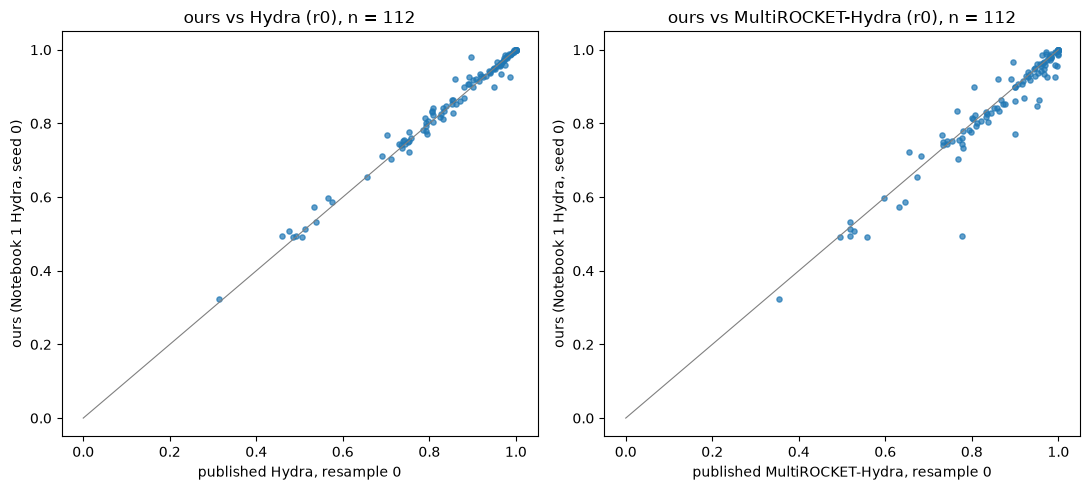

In [11]:
# ---- C3. (b) our default-split Hydra vs published resample 0 ----
if RUN_PART_C or csv_exists(PARTC_CSV):
    ours = PARTC_LONG[PARTC_LONG["estimator"] == "Hydra (ours, Notebook 1)"].set_index("dataset")["accuracy"]
    ests_r0 = [e for e in PARTC_ESTIMATORS if len(pub_series(e, "resample0"))]
    tb = pair_table([(f"Hydra ours (r0) - {e} (r0)", ours, pub_series(e, "resample0")) for e in ests_r0], "ours", "other")
    tb["other"] = ests_r0
    save_csv(tb, out("repro_partC_ours_vs_published_r0.csv"))
    print("(b) our default-split Hydra (Notebook 1, seed 0) vs published resample 0:")
    display(tb[["other", "n", "mean_ours", "mean_other", "mean_delta_pp", "W/D/L", "W/D/L_exact", "p", "p_holm"]].round(4))

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, e in zip(axes, ["Hydra", "MultiROCKET-Hydra"]):
        p = pub_series(e, "resample0")
        if p.empty:
            ax.set_title(f"{e}: not available")
            continue
        both = pd.concat([ours, p], axis=1, keys=["ours", "pub"]).dropna()
        diff = (both["ours"] - both["pub"]) * 100
        print(f"\nours vs published {e} resample 0: n={len(both)}, mean |diff| = {diff.abs().mean():.2f} pp, "
              f"mean diff = {diff.mean():+.2f} pp, datasets with |diff| > 5 pp: {int((diff.abs() > 5).sum())}")
        big = diff[diff.abs() > 5].sort_values()
        if len(big):
            display(pd.DataFrame({"ours": both.loc[big.index, "ours"], f"{e}_r0": both.loc[big.index, "pub"],
                                  "diff_pp": big.round(2)}))
        ax.scatter(both["pub"], both["ours"], s=14, alpha=0.7)
        ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
        ax.set_xlabel(f"published {e}, resample 0")
        ax.set_ylabel("ours (Notebook 1 Hydra, seed 0)")
        ax.set_title(f"ours vs {e} (r0), n = {len(both)}")
    plt.tight_layout(); plt.savefig(fig_path("repro_partC_scatter_r0"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()

(c) mean ranks on resample 0 over 112 datasets with every estimator present:


,mean_rank,mean_acc,n_datasets
HC2,4.3080,0.8764,112
MultiROCKET-Hydra,5.1562,0.8680,112
MultiROCKET,5.5134,0.8657,112
Hydra (ours),6.4241,0.8577,112
TS-CHIEF,6.4955,0.8648,112
InceptionTime,6.5804,0.8578,112
ROCKET,6.7321,0.8558,112
Hydra,7.0045,0.8535,112
MiniROCKET,7.1696,0.8580,112
MrSQM,7.1875,0.8534,112


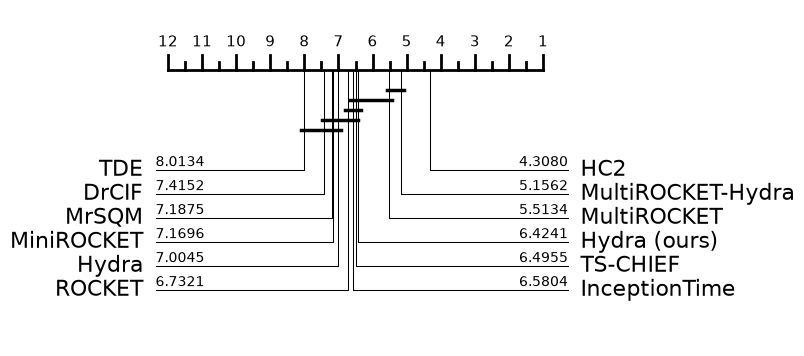

In [12]:
# ---- C4. (c) mean ranks on resample 0 and critical-difference diagram ----
if RUN_PART_C or csv_exists(PARTC_CSV):
    cols = {"Hydra (ours)": ours}
    cols.update({e: pub_series(e, "resample0") for e in ests_r0})
    R0 = pd.DataFrame(cols).dropna()
    ranks = R0.rank(axis=1, ascending=False, method="average")
    rank_table = pd.DataFrame({"mean_rank": ranks.mean(), "mean_acc": R0.mean(), "n_datasets": len(R0)}).sort_values("mean_rank")
    save_csv(rank_table.reset_index(names="estimator"), out("repro_partC_ranks.csv"))
    print(f"(c) mean ranks on resample 0 over {len(R0)} datasets with every estimator present:")
    display(rank_table.round(4))
    try:
        from aeon.visualisation import plot_critical_difference
        fig, ax = plot_critical_difference(R0.to_numpy(), list(R0.columns))
        fig.savefig(fig_path("repro_partC_cd_r0"), dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)
    except Exception as exc:
        print("critical-difference plot failed:", type(exc).__name__, exc)

In [13]:
# ---- C5. outlier cross-check ----
if RUN_PART_C or csv_exists(PARTC_CSV):
    oc = pd.DataFrame({"ours_r0": NB1["accuracy"].reindex(OUTLIERS), "authors_mean30": AUTH.reindex(OUTLIERS),
                       "pub_hydra_r0": pub_series("Hydra", "resample0").reindex(OUTLIERS),
                       "pub_hydra_mean30": pub_series("Hydra", "mean30").reindex(OUTLIERS)})
    oc["ours_r0_minus_authors_pp"] = (oc["ours_r0"] - oc["authors_mean30"]) * 100
    oc["pub_r0_minus_pub_mean30_pp"] = (oc["pub_hydra_r0"] - oc["pub_hydra_mean30"]) * 100
    oc["ours_r0_minus_pub_r0_pp"] = (oc["ours_r0"] - oc["pub_hydra_r0"]) * 100
    oc = oc.sort_values("ours_r0_minus_authors_pp")
    save_csv(oc.reset_index(names="dataset"), out("repro_partC_outliers.csv"))
    print("Outliers: our default split vs the authors' 30-resample mean and published Hydra (resample 0 and 30-resample mean):")
    display(oc.round(4))
    print("mean over the outliers (pp):", oc[["ours_r0_minus_authors_pp", "pub_r0_minus_pub_mean30_pp",
                                              "ours_r0_minus_pub_r0_pp"]].mean().round(2).to_dict())

Outliers: our default split vs the authors' 30-resample mean and published Hydra (resample 0 and 30-resample mean):


,ours_r0,authors_mean30,pub_hydra_r0,pub_hydra_mean30,ours_r0_minus_authors_pp,pub_r0_minus_pub_mean30_pp,ours_r0_minus_pub_r0_pp
dataset,,,,,,,
EOGVerticalSignal,0.4945,0.7640,0.4917,0.7647,-26.9521,-27.3020,0.2762
EOGHorizontalSignal,0.5718,0.8270,0.5331,0.8198,-25.5157,-28.6648,3.8674
RefrigerationDevices,0.5067,0.7561,0.4747,0.7324,-24.9422,-25.7689,3.2000
ScreenType,0.4907,0.6241,0.4853,0.5793,-13.3422,-9.3956,0.5333
ElectricDevices,0.7531,0.8817,0.7380,0.8708,-12.8591,-13.2789,1.5043
Computers,0.7040,0.8185,0.7120,0.8120,-11.4533,-10.0000,-0.8000
FordB,0.8247,0.9322,0.8259,0.9292,-10.7490,-10.3251,-0.1235
Ham,0.7429,0.8476,0.7429,0.8444,-10.4762,-10.1587,0.0000
FaceAll,0.8988,0.9843,0.8793,0.9829,-8.5483,-10.3629,1.9527


mean over the outliers (pp): {'ours_r0_minus_authors_pp': -8.91, 'pub_r0_minus_pub_mean30_pp': -8.76, 'ours_r0_minus_pub_r0_pp': 0.66}


---
# Part D: 30 resamples on the 18 outlier datasets

**Claim checked (C5).** Are the 18 datasets where our default-split accuracy is more than 5 pp from the paper explained by the split (resampling noise and a hard default split), by the data (normalisation), or by our code?

**Protocol.**
- Resample 0 is the default UCR split; resamples 1–29 come from `make_split` (pool train+test, draw a new train set with the same per-class counts using `RandomState(resample_id)`, no overlap; sizes asserted).
- The Hydra kernel seed is the resample id. Pipeline as `01_hydra_baseline.ipynb`: official Hydra k = 8, g = 64 → `SparseScaler` (train only) → `RidgeClassifierCV(np.logspace(-3, 3, 10))`.
- **Check:** resample 0 with seed 0 must reproduce `01_hydra_baseline.ipynb`'s accuracy for every outlier exactly; mismatches are printed.
- **Normalisation scan** (all 112 datasets, training series only): the mean over series of the per-series mean and standard deviation; flagged *unnormalised* when |mean of means| > 0.1 or |mean std − 1| > 0.1.
- **EOG diagnostic (a diagnostic, not part of the reproduction):** EOGVerticalSignal and EOGHorizontalSignal rerun on the same 30 resamples with per-series z-normalisation of train and test inputs; same kernels and seeds.

**Differences from the paper.** The authors' 30 resamples were drawn by the Java tsml code; our draws do not replicate them, so agreement is expected **within sampling noise**, not number for number. The 95% CI is a t-interval over our 30 resamples (it describes our resample mean, not the authors' draw).

In [14]:
if RUN_PART_D:
    if set(OUTLIERS) != set(EXPECTED_OUTLIERS):
        print("WARNING: recomputed outliers differ from the expected list (see the outlier cell above)")
    assert len(OUTLIERS) == 18, f"expected 18 outliers, found {len(OUTLIERS)}"
    log_check("18 outliers recomputed from Notebook 1 and the authors' CSV")

    # ---- D3. normalisation scan (training series only) ----
    if not csv_exists(PARTD_SCAN_CSV):
        scan = []
        for d in SCAN_DATASETS:
            try:
                Xtr, _, _, _ = load_ucr_dataset(d)
                s = Xtr[:, 0, :].astype(np.float64)
                mm, ms = float(s.mean(axis=1).mean()), float(s.std(axis=1).mean())
                scan.append({"dataset": d, "mean_of_means": mm, "mean_of_stds": ms,
                             "unnormalised": bool(abs(mm) > 0.1 or abs(ms - 1) > 0.1)})
            except Exception as exc:
                log_failure("D-scan", d, exc)
        save_csv(pd.DataFrame(scan), PARTD_SCAN_CSV)
    scan_df = pd.read_csv(PARTD_SCAN_CSV)
    print(f"normalisation scan: {int(scan_df['unnormalised'].sum())} of {len(scan_df)} datasets flagged unnormalised")
    display(scan_df[scan_df["unnormalised"]].round(3))

CHECK PASS: 18 outliers recomputed from Notebook 1 and the authors' CSV
normalisation scan: 21 of 112 datasets flagged unnormalised


,dataset,mean_of_means,mean_of_stds,unnormalised
3,BME,0.058,0.504,True
9,Chinatown,636.325,511.240,True
17,Crop,0.450,0.130,True
25,EOGHorizontalSignal,-12.928,95.112,True
26,EOGVerticalSignal,4.192,91.526,True
40,GunPointAgeSpan,606.867,147.402,True
41,GunPointMaleVersusFemale,607.161,148.139,True
42,GunPointOldVersusYoung,589.306,146.598,True
47,HouseTwenty,789.155,812.361,True
49,InsectEPGRegularTrain,0.811,0.046,True


In [15]:
D_COLS = ["dataset", "resample", "seed", "znorm", "acc", "macro_f1", "alpha", "alpha_at_edge", "n_features",
          "n_train", "n_test", "train_transform_s", "test_transform_s", "fit_s"]

def run_partD_unit(ds, r, znorm, raw):
    Xtr, ytr, Xte, yte = make_split(*raw, r)
    if znorm:
        Xtr, Xte = znorm_series(Xtr), znorm_series(Xte)
    model = Hydra(Xtr.shape[-1], k=8, g=64, seed=r)
    t = perf_counter(); Ztr = hydra_features(model, Xtr); ttr = perf_counter() - t
    t = perf_counter(); Zte = hydra_features(model, Xte); tte = perf_counter() - t
    t = perf_counter(); res = fit_ridge(Ztr, ytr, Zte, yte, AUTHOR_ALPHAS); tfit = perf_counter() - t
    return {"dataset": ds, "resample": r, "seed": r, "znorm": bool(znorm), "acc": res["acc"], "macro_f1": res["macro_f1"],
            "alpha": res["alpha"], "alpha_at_edge": res["alpha_at_edge"], "n_features": res["n_features"],
            "n_train": len(ytr), "n_test": len(yte), "train_transform_s": ttr, "test_transform_s": tte, "fit_s": tfit}

if RUN_PART_D:
    d_names = by_cost(D_DATASETS if D_DATASETS is not None else OUTLIERS)
    units = [(d, r, False) for d in d_names for r in D_RESAMPLES]
    units += [(d, r, True) for d in by_cost([d for d in D_ZNORM_DATASETS if d in d_names]) for r in D_RESAMPLES]
    done = completed_units(PARTD_CSV, ["dataset", "resample", "znorm"])
    todo = [u for u in units if (u[0], u[1], u[2]) not in done]
    print(f"Part D: {len(units) - len(todo)} units already complete, {len(todo)} to run")
    prog, raw_cache = Progress("D", [COST[u[0]] for u in todo]), {}
    for ds, r, zn in todo:
        try:
            if ds not in raw_cache:
                raw_cache.clear(); gc.collect()
                raw_cache[ds] = load_ucr_dataset(ds)
            row = run_partD_unit(ds, r, zn, raw_cache[ds])
            append_csv(pd.DataFrame([row])[D_COLS], PARTD_CSV)
            msg = f"{ds:30s} r{r:<2d} znorm={zn!s:5s} acc {row['acc']:.4f}"
        except Exception as exc:
            log_failure("D", (ds, r, zn), exc); msg = f"{ds} r{r} FAILED"
        prog.step(COST[ds], msg)
    raw_cache.clear(); gc.collect()

Part D: 0 units already complete, 600 to run
[D     0.0 min | ETA ~ 152.7 min] 1/600 BeetleFly                      r0  znorm=False acc 0.9000
[D     0.0 min | ETA ~ 140.2 min] 2/600 BeetleFly                      r1  znorm=False acc 0.9500
[D     0.0 min | ETA ~ 134.9 min] 3/600 BeetleFly                      r2  znorm=False acc 0.9500
[D     0.0 min | ETA ~ 132.6 min] 4/600 BeetleFly                      r3  znorm=False acc 0.9500
[D     0.0 min | ETA ~ 131.1 min] 5/600 BeetleFly                      r4  znorm=False acc 1.0000
[D     0.0 min | ETA ~ 129.8 min] 6/600 BeetleFly                      r5  znorm=False acc 0.9000
[D     0.0 min | ETA ~ 129.2 min] 7/600 BeetleFly                      r6  znorm=False acc 0.9000
[D     0.1 min | ETA ~ 128.4 min] 8/600 BeetleFly                      r7  znorm=False acc 0.9500
[D     0.1 min | ETA ~ 128.0 min] 9/600 BeetleFly                      r8  znorm=False acc 1.0000
[D     0.1 min | ETA ~ 127.8 min] 10/600 BeetleFly                      r

CHECK PASS: Part D resample 0 (seed 0) reproduces Notebook 1 exactly for 18 datasets
Part D: 18 datasets; resamples per dataset: [30]


,dataset,n_resamples,paper_mean30,ours_r0,ours_mean,ours_std,ci95_lo,ci95_hi,ours_mean_minus_paper_pp,paper_in_ci95,default_split_penalty_pp,ours_r0_minus_paper_pp,unnormalised,znorm_mean,znorm_n,alpha_edge_rate
0,BeetleFly,30.0,0.9517,0.9000,0.9433,0.0521,0.9239,0.9628,-0.8334,True,-4.3333,-5.1667,False,NaN,0.0,0.9333
1,Ham,30.0,0.8476,0.7429,0.8403,0.0372,0.8264,0.8542,-0.7302,True,-9.7460,-10.4762,False,NaN,0.0,0.7333
2,Meat,30.0,0.9839,0.9167,0.9778,0.0229,0.9692,0.9863,-0.6111,True,-6.1111,-6.7222,False,NaN,0.0,1.0000
3,EOGVerticalSignal,30.0,0.7640,0.4945,0.7613,0.0522,0.7418,0.7808,-0.2670,True,-26.6851,-26.9521,True,0.7443,30.0,0.3333
4,DistalPhalanxOutlineAgeGroup,30.0,0.8062,0.7554,0.8046,0.0249,0.7953,0.8138,-0.1679,True,-4.9161,-5.0839,False,NaN,0.0,1.0000
5,LargeKitchenAppliances,30.0,0.9356,0.8533,0.9350,0.0193,0.9278,0.9422,-0.0534,True,-8.1689,-8.2223,False,NaN,0.0,0.1667
6,FordB,30.0,0.9322,0.8247,0.9324,0.0222,0.9241,0.9407,0.0206,True,-10.7695,-10.7490,False,NaN,0.0,1.0000
7,FaceAll,30.0,0.9843,0.8988,0.9848,0.0165,0.9786,0.9909,0.0473,True,-8.5957,-8.5483,False,NaN,0.0,0.0667
8,ElectricDevices,30.0,0.8817,0.7531,0.8827,0.0247,0.8735,0.8919,0.1020,True,-12.9611,-12.8591,False,NaN,0.0,1.0000
9,Computers,30.0,0.8185,0.7040,0.8203,0.0282,0.8097,0.8308,0.1734,True,-11.6267,-11.4533,False,NaN,0.0,0.4667


EOG diagnostic (per-series z-normalisation; diagnostic only):


,plain_mean,znorm_mean,paper_mean30,znorm_minus_plain_pp,znorm_minus_paper_pp
dataset,,,,,
EOGHorizontalSignal,0.8334,0.8154,0.827,-1.8048,-1.1602
EOGVerticalSignal,0.7613,0.7443,0.764,-1.7035,-1.9705


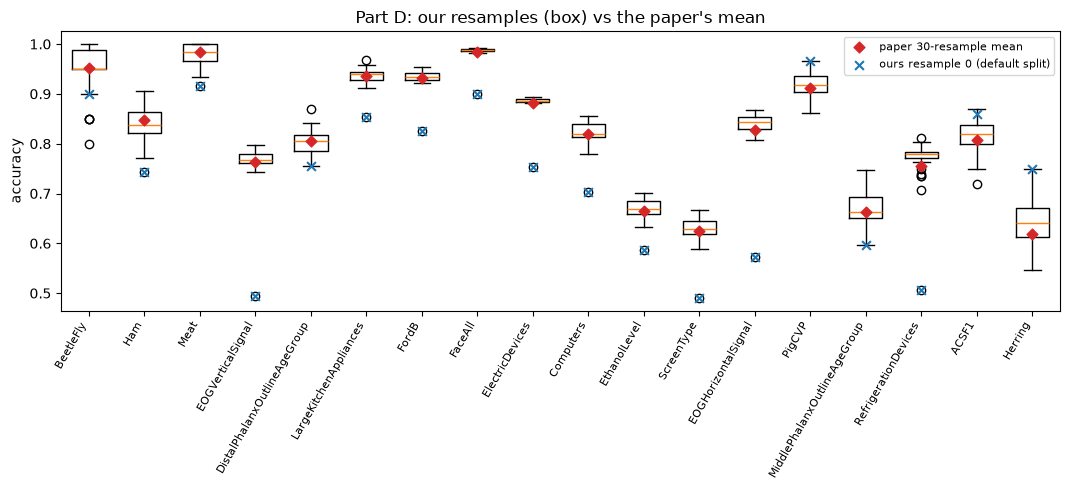

In [16]:
# ---- D5. summary table ----
if csv_exists(PARTD_CSV):
    dres = pd.read_csv(PARTD_CSV)
    dres["znorm"] = dres["znorm"].astype(str).str.lower().eq("true")
    plain, zn = dres[~dres["znorm"]], dres[dres["znorm"]]

    # check: resample 0 (seed 0) reproduces 01_hydra_baseline.ipynb exactly
    r0 = plain[plain["resample"] == 0].set_index("dataset")["acc"]
    mism = (r0 - NB1["accuracy"].reindex(r0.index)).abs()
    if (mism > 1e-12).any():
        print("MISMATCH resample 0 vs Notebook 1:"); display(pd.DataFrame({"ours_r0": r0, "nb1": NB1["accuracy"].reindex(r0.index)})[mism > 1e-12])
    else:
        log_check(f"Part D resample 0 (seed 0) reproduces Notebook 1 exactly for {len(r0)} datasets")

    scan_flag = read_csv_safe(PARTD_SCAN_CSV)
    scan_flag = scan_flag.set_index("dataset")["unnormalised"] if len(scan_flag) else pd.Series(dtype=bool)
    rows = []
    for ds, g in plain.groupby("dataset"):
        a = g.sort_values("resample")["acc"].to_numpy(); n = len(a)
        m, sd = a.mean(), a.std(ddof=1) if n > 1 else float("nan")
        half = sstats.t.ppf(0.975, n - 1) * sd / math.sqrt(n) if n > 1 else float("nan")
        paper = AUTH.get(ds, np.nan)
        r0v = g.loc[g["resample"] == 0, "acc"]
        zg = zn[zn["dataset"] == ds]["acc"]
        rows.append({"dataset": ds, "n_resamples": n, "paper_mean30": paper,
                     "ours_r0": float(r0v.iloc[0]) if len(r0v) else np.nan, "ours_mean": m, "ours_std": sd,
                     "ci95_lo": m - half, "ci95_hi": m + half, "ours_mean_minus_paper_pp": (m - paper) * 100,
                     "paper_in_ci95": bool(m - half <= paper <= m + half) if n > 1 else None,
                     "default_split_penalty_pp": ((float(r0v.iloc[0]) - m) * 100) if len(r0v) else np.nan,
                     "ours_r0_minus_paper_pp": ((float(r0v.iloc[0]) - paper) * 100) if len(r0v) else np.nan,
                     "unnormalised": scan_flag.get(ds, None),
                     "znorm_mean": zg.mean() if len(zg) else np.nan, "znorm_n": len(zg),
                     "alpha_edge_rate": g["alpha_at_edge"].astype(str).str.lower().eq("true").mean()})
    dsum = pd.DataFrame(rows).sort_values("ours_mean_minus_paper_pp")
    summ = {"dataset": "MEAN over datasets", "ours_mean_minus_paper_pp": dsum["ours_mean_minus_paper_pp"].mean(),
            "ours_r0_minus_paper_pp": dsum["ours_r0_minus_paper_pp"].mean(),
            "default_split_penalty_pp": dsum["default_split_penalty_pp"].mean(),
            "paper_in_ci95": f"{int(dsum['paper_in_ci95'].fillna(False).astype(bool).sum())}/{len(dsum)}"}
    dsum_out = pd.concat([dsum, pd.DataFrame([summ])], ignore_index=True)
    save_csv(dsum_out, out("repro_partD_summary.csv"))
    print(f"Part D: {len(dsum)} datasets; resamples per dataset: {sorted(dsum['n_resamples'].unique().tolist())}")
    display(dsum_out.round(4))
    if len(zn):
        zt = pd.DataFrame({"plain_mean": plain.groupby("dataset")["acc"].mean(), "znorm_mean": zn.groupby("dataset")["acc"].mean(),
                           "paper_mean30": AUTH}).dropna(subset=["znorm_mean"])
        zt["znorm_minus_plain_pp"] = (zt["znorm_mean"] - zt["plain_mean"]) * 100
        zt["znorm_minus_paper_pp"] = (zt["znorm_mean"] - zt["paper_mean30"]) * 100
        print("EOG diagnostic (per-series z-normalisation; diagnostic only):"); display(zt.round(4))

    # figure: per-outlier resample distribution vs the paper's mean
    order = dsum["dataset"].tolist()
    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(order)), 5))
    ax.boxplot([plain[plain["dataset"] == d]["acc"] for d in order], positions=range(len(order)), widths=0.6)
    ax.scatter(range(len(order)), [AUTH[d] for d in order], color="tab:red", marker="D", s=30, label="paper 30-resample mean", zorder=3)
    ax.scatter(range(len(order)), dsum["ours_r0"], color="tab:blue", marker="x", s=40, label="ours resample 0 (default split)", zorder=3)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
    ax.set_ylabel("accuracy"); ax.set_title("Part D: our resamples (box) vs the paper's mean"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(fig_path("repro_partD_resamples"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()

---
# Part B: Rocket family on all 112 datasets (default split, Aarti's corrected pipeline)

**Claim checked (C3).** Hydra+MultiRocket is more accurate than MultiRocket and than Hydra. Also places Hydra next to MiniRocket and MultiRocket on the same splits.

**Protocol.**
- Default UCR split, data loaded exactly as `01_hydra_baseline.ipynb` (float32; aeon's Rocket transforms cast to float32 anyway).
- **Configurations copied from Aarti** (cell below): MiniRocket 10,000 kernels, max 32 dilations; MultiRocket 6,250 kernels, max 32 dilations, 4 features per kernel, `normalise=False`; `random_state = 42` for both. Hydra: official class, k = 8, g = 64, **seed 0**, so standalone Hydra must reproduce `01_hydra_baseline.ipynb`.
- **Scaling:** Hydra block `SparseScaler`; MultiRocket and MiniRocket blocks `StandardScaler` fitted on train (Aarti's fix, as in aeon's `MultiRocketHydraClassifier`). Standalone MultiRocket uses the same scaled block as the combination (see Step 0 for why this equals aeon's `StandardScaler(with_mean=False)` pipeline; a check prints the difference). Every model: `RidgeClassifierCV(np.logspace(-3, 3, 10))`.
- Each feature block is computed **once** per dataset and reused. Rocket test features are transformed and predicted in chunks of 2,048 cases (identical results, bounded memory).
- Numba JIT compilation is excluded from timings: one warm-up of MiniRocket and MultiRocket on a tiny synthetic array runs first.

**Differences.** Aarti's standalone MiniRocket/MultiRocket used raw features (now scaled); Hydra seed 42 → 0; `n_jobs=1` → all threads. The paper reports 30-resample means; this part uses the default split only.

### Copied from aarti_combined_experiments.ipynb

In [17]:
# ===================== Copied from aarti_combined_experiments.ipynb =====================
# Source cells (0-based cell index in her notebook): 7 (MiniRocket run_dataset), 18 (MultiRocket run_dataset),
# 28 (Hydra + MultiRocket run_dataset, including the StandardScaler FIX). Her code lives inside run_dataset();
# here the same lines are wrapped in small functions so that Part B computes every feature block ONCE per dataset
# and reuses it (standalone model and combination). Lines that differ from her source are marked "# CHANGED:".
# Function headers / return statements are new wrappers (marked "# WRAPPER").

def make_minirocket():  # WRAPPER (body from cell 7)
    model = MiniRocket(n_kernels=10000, max_dilations_per_kernel=32,
                       n_jobs=N_JOBS, random_state=RANDOM_STATE)  # CHANGED: n_jobs=1 -> N_JOBS (all threads)
    return model  # WRAPPER


def make_multirocket():  # WRAPPER (body from cell 18; identical constructor in cell 28)
    model = MultiRocket(n_kernels=6250, max_dilations_per_kernel=32,
                       n_features_per_kernel=4, normalise=False,
                       n_jobs=N_JOBS, random_state=RANDOM_STATE)  # CHANGED: n_jobs=1 -> N_JOBS (all threads)
    return model  # WRAPPER


def timed_fit_transform(model, X_train):  # WRAPPER (timing pattern from cells 7 and 18)
    start = perf_counter()
    X_train_features = model.fit_transform(X_train)
    train_transform = perf_counter() - start
    return X_train_features, train_transform  # WRAPPER


def timed_transform(model, X_test):  # WRAPPER (timing pattern from cells 7 and 18)
    start = perf_counter()
    X_test_features = model.transform(X_test)
    test_transform = perf_counter() - start
    return X_test_features, test_transform  # WRAPPER


def hydra_block(X_train, X_test, seed):  # WRAPPER (body from cell 28)
    X_train_tensor = torch.as_tensor(np.ascontiguousarray(X_train), dtype=torch.float32)
    X_test_tensor = torch.as_tensor(np.ascontiguousarray(X_test), dtype=torch.float32)
    hydra = Hydra(input_length=X_train.shape[-1], k=8, g=64, seed=seed)  # CHANGED: seed=RANDOM_STATE (42) -> seed argument; Part B passes 0 (= 01_hydra_baseline.ipynb)

    start = perf_counter()
    with torch.inference_mode():
        H_train_tensor = hydra.batch(X_train_tensor, batch_size=BATCH_SIZE)
    hydra_train_time = perf_counter() - start

    start = perf_counter()
    with torch.inference_mode():
        H_test_tensor = hydra.batch(X_test_tensor, batch_size=BATCH_SIZE)
    hydra_test_time = perf_counter() - start

    scaler = SparseScaler()
    H_train_tensor = scaler.fit_transform(H_train_tensor)
    H_test_tensor = scaler.transform(H_test_tensor)
    H_train = H_train_tensor.detach().cpu().numpy()
    H_test = H_test_tensor.detach().cpu().numpy()
    return H_train, H_test, hydra_train_time, hydra_test_time  # WRAPPER


def multirocket_block_train(X_train):  # WRAPPER (body from cell 28)
    mr = MultiRocket(n_kernels=6250, max_dilations_per_kernel=32,
                     n_features_per_kernel=4, normalise=False,
                     n_jobs=N_JOBS, random_state=RANDOM_STATE)  # CHANGED: n_jobs=1 -> N_JOBS (all threads)
    # FIX: MultiRocket features must be standardised before concatenation.
    # Raw MultiRocket features are ~20x larger than the SparseScaler-scaled Hydra
    # features, so with a single ridge penalty the Hydra block was effectively
    # ignored (predictions were identical to MultiRocket alone). This matches the
    # reference implementation (aeon MultiRocketHydraClassifier): SparseScaler for
    # Hydra, StandardScaler for MultiRocket, fitted on training data only.
    mr_scaler = StandardScaler()
    start = perf_counter()
    M_train = np.asarray(mr.fit_transform(X_train), dtype=np.float32)
    M_train = mr_scaler.fit_transform(M_train).astype(np.float32)
    mr_train_time = perf_counter() - start
    return mr, mr_scaler, M_train, mr_train_time  # WRAPPER


def multirocket_block_test(mr, mr_scaler, X_test):  # WRAPPER (body from cell 28). CHANGED: Part B calls it on test CHUNKS (memory)
    start = perf_counter()
    M_test = np.asarray(mr.transform(X_test), dtype=np.float32)
    M_test = mr_scaler.transform(M_test).astype(np.float32)
    mr_test_time = perf_counter() - start
    return M_test, mr_test_time  # WRAPPER


def concat_blocks(H_train, M_train, H_test=None, M_test=None):  # WRAPPER (lines from cell 28)
    Z_train = np.concatenate([H_train, M_train], axis=1) if M_train is not None else None  # CHANGED: optional (train and test chunks are built at different times)
    Z_test = np.concatenate([H_test, M_test], axis=1) if M_test is not None else None  # CHANGED: optional (see above)
    return Z_train, Z_test  # WRAPPER


def ridge_fit(Z_train, y_train):  # WRAPPER (first half of the ridge lines in cell 28)
    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    start = perf_counter()
    classifier.fit(Z_train, y_train)
    classifier_fit = perf_counter() - start
    return classifier, classifier_fit  # WRAPPER


def ridge_predict(classifier, Z_test):  # WRAPPER (second half of the ridge lines in cell 28)
    start = perf_counter()
    y_pred = classifier.predict(Z_test)
    prediction = perf_counter() - start
    return y_pred, prediction  # WRAPPER

In [18]:
B_MODELS = ["Hydra", "MiniRocket", "MultiRocket", "Hydra+MultiRocket"] + (["Hydra+MiniRocket"] if INCLUDE_H_MINI else [])
B_COLS = ["dataset", "model", "n_train", "n_test", "length", "n_classes", "n_features", "acc", "macro_f1", "alpha",
          "alpha_at_edge", "train_transform_s", "test_transform_s", "fit_s", "predict_s", "same_preds_as_partner", "unit_s"]
B_SCALE_CHECK = {"done": False}
B_WITHMEAN_CHECK_N = 3          # datasets on which the aeon StandardScaler(with_mean=False) variant is also fitted


def chunks(n, size=TEST_CHUNK):
    return [np.arange(i, min(i + size, n)) for i in range(0, n, size)]


def b_row(ds, model, Xtr, ytr, yte, n_features, clf, pred, ttr, tte, tfit, tpred, partner_pred=None):
    return {"dataset": ds, "model": model, "n_train": len(ytr), "n_test": len(yte), "length": Xtr.shape[-1],
            "n_classes": len(np.unique(ytr)), "n_features": int(n_features), "acc": accuracy_score(yte, pred),
            "macro_f1": f1_score(yte, pred, average="macro", zero_division=0), "alpha": float(clf.alpha_),
            "alpha_at_edge": alpha_at_edge(clf.alpha_, AUTHOR_ALPHAS), "train_transform_s": ttr, "test_transform_s": tte,
            "fit_s": tfit, "predict_s": tpred,
            "same_preds_as_partner": (bool(np.array_equal(pred, partner_pred)) if partner_pred is not None else None),
            "unit_s": np.nan}


def run_partB_dataset(ds, check_with_mean=False):
    t_unit = perf_counter()
    X_train, y_train, X_test, y_test = load_ucr_dataset(ds)
    rows, preds = [], {}
    # ---- Hydra block (once) ----
    H_train, H_test, h_tr, h_te = hydra_block(X_train, X_test, HYDRA_SEED_B)
    clf, tfit = ridge_fit(H_train, y_train)
    pred, tpred = ridge_predict(clf, H_test)
    preds["Hydra"] = pred
    rows.append(b_row(ds, "Hydra", X_train, y_train, y_test, H_train.shape[1], clf, pred, h_tr, h_te, tfit, tpred))

    # ---- MiniRocket block (once): same StandardScaler pattern as Aarti's MultiRocket fix ----
    mini = make_minirocket()
    Mi_train, mi_tr = timed_fit_transform(mini, X_train)
    t = perf_counter(); mi_scaler = StandardScaler(); Mi_train = mi_scaler.fit_transform(np.asarray(Mi_train, dtype=np.float32)).astype(np.float32); mi_tr += perf_counter() - t
    clf_mi, tfit_mi = ridge_fit(Mi_train, y_train)
    if INCLUDE_H_MINI:
        Z_train, _ = concat_blocks(H_train, Mi_train)
        clf_hmi, tfit_hmi = ridge_fit(Z_train, y_train); del Z_train
    if check_with_mean:
        mi_aeon_sc = StandardScaler(with_mean=False)
        clf_mi_aeon, _ = ridge_fit(mi_aeon_sc.fit_transform(np.asarray(mini.transform(X_train), dtype=np.float32)).astype(np.float32), y_train)
    del Mi_train; gc.collect()

    # ---- MultiRocket block (once), Aarti's FIX: StandardScaler on the MultiRocket block ----
    mr, mr_scaler, M_train, mr_tr = multirocket_block_train(X_train)
    if not B_SCALE_CHECK["done"]:
        print(f"  block scales after scaling ({ds}, train): mean|Hydra| = {np.abs(H_train).mean():.3f}, "
              f"mean|MultiRocket| = {np.abs(M_train).mean():.3f}, ratio = {np.abs(M_train).mean() / max(np.abs(H_train).mean(), 1e-12):.2f}")
        B_SCALE_CHECK["done"] = True
    clf_mr, tfit_mr = ridge_fit(M_train, y_train)
    if check_with_mean:
        aeon_sc = StandardScaler(with_mean=False)
        clf_mr_aeon, _ = ridge_fit(aeon_sc.fit_transform(np.asarray(mr.transform(X_train), dtype=np.float32)).astype(np.float32), y_train)
    Z_train, _ = concat_blocks(H_train, M_train)
    del M_train; gc.collect()
    clf_hmr, tfit_hmr = ridge_fit(Z_train, y_train)
    del Z_train; gc.collect()

    # ---- test set in chunks: transform once, predict every model that uses the block ----
    acc_pred = {m: [] for m in ["MiniRocket", "Hydra+MiniRocket", "MultiRocket", "Hydra+MultiRocket", "mini_aeon", "mr_aeon"]}
    tp = {m: 0.0 for m in acc_pred}
    mi_te = mr_te = 0.0
    for idx in chunks(len(y_test)):
        Mi_c, tt = timed_transform(mini, X_test[idx])
        t = perf_counter(); Mi_c = mi_scaler.transform(np.asarray(Mi_c, dtype=np.float32)).astype(np.float32); mi_te += tt + perf_counter() - t
        p, s = ridge_predict(clf_mi, Mi_c); acc_pred["MiniRocket"].append(p); tp["MiniRocket"] += s
        if INCLUDE_H_MINI:
            _, Z_c = concat_blocks(None, None, H_test[idx], Mi_c)
            p, s = ridge_predict(clf_hmi, Z_c); acc_pred["Hydra+MiniRocket"].append(p); tp["Hydra+MiniRocket"] += s
        if check_with_mean:
            acc_pred["mini_aeon"].append(clf_mi_aeon.predict(mi_aeon_sc.transform(np.asarray(mini.transform(X_test[idx]), dtype=np.float32))))
        M_c, tt = multirocket_block_test(mr, mr_scaler, X_test[idx]); mr_te += tt
        p, s = ridge_predict(clf_mr, M_c); acc_pred["MultiRocket"].append(p); tp["MultiRocket"] += s
        _, Z_c = concat_blocks(None, None, H_test[idx], M_c)
        p, s = ridge_predict(clf_hmr, Z_c); acc_pred["Hydra+MultiRocket"].append(p); tp["Hydra+MultiRocket"] += s
        if check_with_mean:
            acc_pred["mr_aeon"].append(clf_mr_aeon.predict(aeon_sc.transform(np.asarray(mr.transform(X_test[idx]), dtype=np.float32))))
        del Mi_c, M_c, Z_c
    P = {m: np.concatenate(v) for m, v in acc_pred.items() if v}
    n_mi, n_mr = len(mi_scaler.scale_), len(mr_scaler.scale_)
    rows.append(b_row(ds, "MiniRocket", X_train, y_train, y_test, n_mi, clf_mi, P["MiniRocket"], mi_tr, mi_te, tfit_mi, tp["MiniRocket"]))
    rows.append(b_row(ds, "MultiRocket", X_train, y_train, y_test, n_mr, clf_mr, P["MultiRocket"], mr_tr, mr_te, tfit_mr, tp["MultiRocket"]))
    rows.append(b_row(ds, "Hydra+MultiRocket", X_train, y_train, y_test, H_train.shape[1] + n_mr, clf_hmr, P["Hydra+MultiRocket"],
                      h_tr + mr_tr, h_te + mr_te, tfit_hmr, tp["Hydra+MultiRocket"], partner_pred=P["MultiRocket"]))
    if INCLUDE_H_MINI:
        rows.append(b_row(ds, "Hydra+MiniRocket", X_train, y_train, y_test, H_train.shape[1] + n_mi, clf_hmi, P["Hydra+MiniRocket"],
                          h_tr + mi_tr, h_te + mi_te, tfit_hmi, tp["Hydra+MiniRocket"], partner_pred=P["MiniRocket"]))
    if check_with_mean:
        for name, mine, aeon_pred, a1, a2 in [("MiniRocket", P["MiniRocket"], P["mini_aeon"], clf_mi.alpha_, clf_mi_aeon.alpha_),
                                              ("MultiRocket", P["MultiRocket"], P["mr_aeon"], clf_mr.alpha_, clf_mr_aeon.alpha_)]:
            print(f"  scaler check {ds} {name}: StandardScaler() vs aeon StandardScaler(with_mean=False): "
                  f"{int((mine != aeon_pred).sum())} of {len(mine)} predictions differ; alpha {a1:.4g} vs {a2:.4g}")
    out_df = pd.DataFrame(rows)
    out_df["unit_s"] = perf_counter() - t_unit
    return out_df[B_COLS]


if RUN_PART_B:
    # numba JIT warm-up (excluded from timings): tiny synthetic arrays, same dtype as the real data
    _rng = np.random.RandomState(0)
    _Xw = _rng.randn(8, 1, 64).astype(np.float32)
    for _m in [make_minirocket(), make_multirocket()]:
        _m.fit_transform(_Xw); _m.transform(_Xw)
    print("numba warm-up done")

    names = by_cost(B_DATASETS)
    done_df = read_csv_safe(PARTB_CSV)
    done = set(done_df.groupby("dataset")["model"].apply(set).loc[lambda s: s.apply(lambda m: set(B_MODELS) <= m)].index) if len(done_df) else set()
    todo = [d for d in names if d not in done]
    print(f"Part B: {len(names) - len(todo)} datasets complete, {len(todo)} to run (models: {B_MODELS})")
    prog = Progress("B", [COST[d] for d in todo])
    n_checked = len(done)
    for ds in todo:
        try:
            res = run_partB_dataset(ds, check_with_mean=(n_checked < B_WITHMEAN_CHECK_N))
            n_checked += 1
            append_csv(res, PARTB_CSV)
            a = res.set_index("model")["acc"]
            msg = f"{ds:28s} " + " ".join(f"{m} {a[m]:.4f}" for m in B_MODELS) + f" ({res['unit_s'].iloc[0]:.0f}s)"
        except Exception as exc:     # MemoryError included: log it and continue with the next dataset
            log_failure("B", ds, exc); msg = f"{ds} FAILED"
        gc.collect()
        prog.step(COST[ds], msg)

numba warm-up done
Part B: 0 datasets complete, 112 to run (models: ['Hydra', 'MiniRocket', 'MultiRocket', 'Hydra+MultiRocket', 'Hydra+MiniRocket'])
  block scales after scaling (Chinatown, train): mean|Hydra| = 0.641, mean|MultiRocket| = 0.775, ratio = 1.21
  scaler check Chinatown MiniRocket: StandardScaler() vs aeon StandardScaler(with_mean=False): 0 of 343 predictions differ; alpha 0.001 vs 0.001
  scaler check Chinatown MultiRocket: StandardScaler() vs aeon StandardScaler(with_mean=False): 0 of 343 predictions differ; alpha 0.001 vs 0.001
[B     0.0 min | ETA ~ 626.8 min] 1/112 Chinatown                    Hydra 0.9825 MiniRocket 0.9825 MultiRocket 0.9796 Hydra+MultiRocket 0.9796 Hydra+MiniRocket 0.9825 (1s)
  scaler check SonyAIBORobotSurface1 MiniRocket: StandardScaler() vs aeon StandardScaler(with_mean=False): 0 of 601 predictions differ; alpha 0.001 vs 0.001
  scaler check SonyAIBORobotSurface1 MultiRocket: StandardScaler() vs aeon StandardScaler(with_mean=False): 0 of 601 pre

Part B: 112 datasets with all models (112 with any)
CHECK PASS: Part B standalone Hydra (seed 0) equals Notebook 1 on all 112 datasets
Hydra+MultiRocket predictions identical to MultiRocket on 39 of 112 datasets
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Mean accuracy, macro-F1, rank and alpha-at-edge rate per model:


,mean_acc,mean_macro_f1,mean_rank,alpha_edge_rate
model,,,,
Hydra,0.8577,0.8364,3.3750,0.7500
MiniRocket,0.8598,0.8386,3.5625,0.7679
MultiRocket,0.8666,0.8465,2.7991,0.9643
Hydra+MultiRocket,0.8690,0.8492,2.5045,0.9464
Hydra+MiniRocket,0.8656,0.8450,2.7589,0.8125


Pairwise (Holm across these comparisons):


,comparison,n,mean_delta_pp,ci_lo_pp,ci_hi_pp,median_delta_pp,W/D/L,W/D/L_exact,p,p_holm
0,Hydra - MiniRocket,112,-0.2101,-0.9210,0.4509,0.0000,49/21/42,49/19/44,0.9939,0.9939
1,Hydra - MultiRocket,112,-0.8877,-1.7904,-0.0812,-0.2462,35/17/60,36/16/60,0.0078,0.0233
2,Hydra+MultiRocket - MultiRocket,112,0.2463,0.0677,0.4490,0.0000,43/45/24,44/43/25,0.0126,0.0251
3,Hydra+MultiRocket - Hydra,112,1.1340,0.4261,1.9551,0.3895,65/18/29,65/17/30,0.0002,0.0007
4,Hydra+MiniRocket - MiniRocket,112,0.5770,0.1878,0.9687,0.3082,65/30/17,65/30/17,0.0000,0.0000


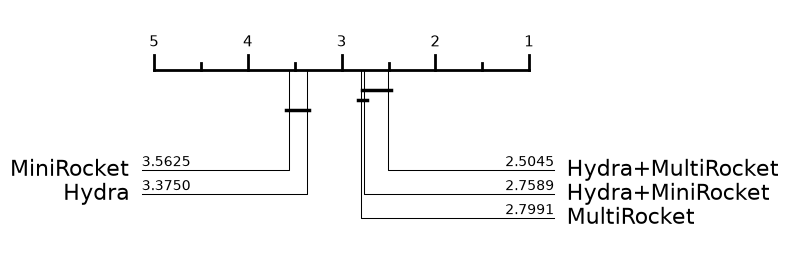

ours Hydra+MultiRocket (default split) - authors' Hydra+MultiRocket (30-resample mean): n=112, mean -1.48 pp, mean |diff| 2.77 pp, |diff| > 5 pp: 19
datasets where Hydra+MultiRocket < Hydra alone: ours 30 of 112 (29 beyond the draw tolerance); authors' file 41 of 112 (task text: 41 of 112)


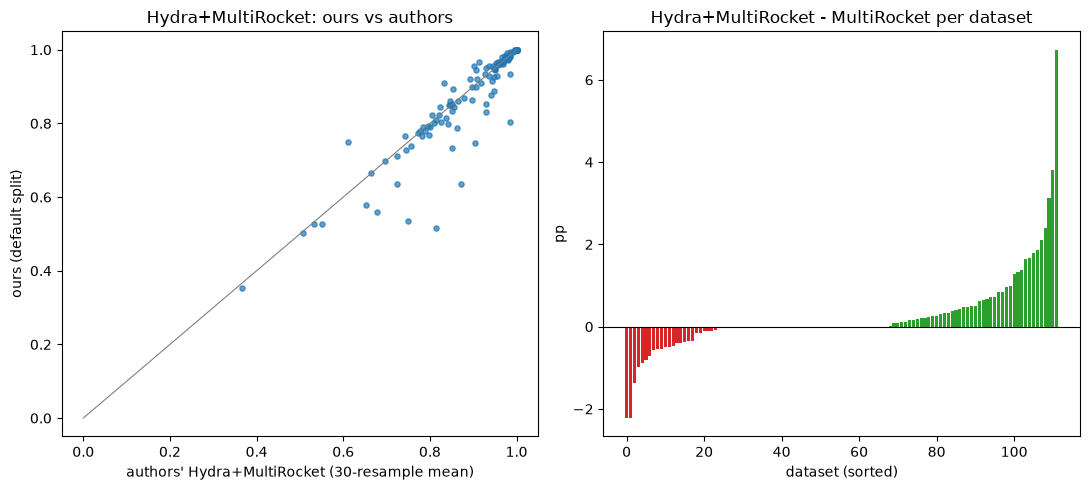

Times (s; sum over datasets and median per dataset). Rocket transform times include their StandardScaler:


train_total_s        test_total_s        train_transform_s  \
                            sum median          sum median               sum   
model                                                                          
Hydra                   316.136  0.672      558.852  1.272           254.616   
MiniRocket              218.892  0.118       18.139  0.048            15.551   
MultiRocket             325.806  0.415      140.182  0.410            83.942   
Hydra+MultiRocket       582.907  1.215      698.410  1.705           338.558   
Hydra+MiniRocket        478.617  0.776      576.895  1.330           270.167   

                         test_transform_s           fit_s        predict_s  \
                  median              sum median      sum median       sum   
model                                                                        
Hydra              0.642          558.526  1.270   61.520  0.017     0.326   
MiniRocket         0.072           17.583  0.046  203.341  0.022     0.556   
MultiRocket        0.305          136.999  0.397  241.865  0.073     3.184   
Hydra+MultiRocket  0.965          695.525  1.695  244.349  0.080     2.885   
Hydra+MiniRocket   0.724          576.110  1.324  208.450  0.034     0.786   

                          
                  median  
model                     
Hydra              0.001  
MiniRocket         0.002  
MultiRocket        0.009  
Hydra+MultiRocket  0.009  
Hydra+MiniRocket   0.003

In [19]:
# ---- B analysis ----
if csv_exists(PARTB_CSV):
    b = pd.read_csv(PARTB_CSV)
    b["alpha_at_edge"] = b["alpha_at_edge"].astype(str).str.lower().eq("true")
    acc = b.pivot(index="dataset", columns="model", values="acc")
    f1 = b.pivot(index="dataset", columns="model", values="macro_f1")
    models = [m for m in B_MODELS if m in acc.columns]
    complete = acc[models].dropna()
    print(f"Part B: {len(complete)} datasets with all models ({len(acc)} with any)")

    # check: standalone Hydra == 01_hydra_baseline.ipynb
    hd = (acc["Hydra"] - NB1["accuracy"].reindex(acc.index)).abs()
    if (hd > 1e-12).any():
        print("MISMATCH standalone Hydra vs Notebook 1:")
        display(pd.DataFrame({"partB": acc["Hydra"], "nb1": NB1["accuracy"].reindex(acc.index)})[hd > 1e-12])
    else:
        log_check(f"Part B standalone Hydra (seed 0) equals Notebook 1 on all {len(acc)} datasets")
    # check: the Hydra block is used
    same = b[b["model"] == "Hydra+MultiRocket"]["same_preds_as_partner"].astype(str).str.lower().eq("true")
    print(f"Hydra+MultiRocket predictions identical to MultiRocket on {int(same.sum())} of {len(same)} datasets")
    if same.sum() > 5:
        print("!" * 80 + "\nWARNING: Hydra+MultiRocket is identical to MultiRocket on more than 5 datasets - "
              "check that the Hydra block is not being ignored\n" + "!" * 80)

    means = pd.DataFrame({"mean_acc": complete.mean(), "mean_macro_f1": f1.loc[complete.index, models].mean(),
                          "mean_rank": complete.rank(axis=1, ascending=False).mean(),
                          "alpha_edge_rate": b.groupby("model")["alpha_at_edge"].mean().reindex(models)}).reindex(models)
    print("Mean accuracy, macro-F1, rank and alpha-at-edge rate per model:"); display(means.round(4))

    pairs = [("Hydra", "MiniRocket"), ("Hydra", "MultiRocket"), ("Hydra+MultiRocket", "MultiRocket"), ("Hydra+MultiRocket", "Hydra")]
    if "Hydra+MiniRocket" in models:
        pairs.append(("Hydra+MiniRocket", "MiniRocket"))
    pt = pair_table([(f"{x} - {y}", complete[x], complete[y]) for x, y in pairs])
    save_csv(pt, out("repro_partB_pairs.csv"))
    print("Pairwise (Holm across these comparisons):"); display(pt.drop(columns=["mean_a", "mean_b"]).round(4))

    try:
        from aeon.visualisation import plot_critical_difference
        fig, ax = plot_critical_difference(complete.to_numpy(), list(complete.columns))
        fig.savefig(fig_path("repro_partB_cd"), dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)
    except Exception as exc:
        print("critical-difference plot failed:", type(exc).__name__, exc)

    # ours vs the authors' Hydra+MultiRocket (30-resample means)
    var = pd.read_csv(AUTHORS_VARIANTS_CSV).set_index("dataset")
    both = pd.concat([complete["Hydra+MultiRocket"], var["Hydra+MultiRocket"]], axis=1, keys=["ours_r0", "authors_mean30"]).dropna()
    dd = (both["ours_r0"] - both["authors_mean30"]) * 100
    print(f"ours Hydra+MultiRocket (default split) - authors' Hydra+MultiRocket (30-resample mean): n={len(both)}, "
          f"mean {dd.mean():+.2f} pp, mean |diff| {dd.abs().mean():.2f} pp, |diff| > 5 pp: {int((dd.abs() > 5).sum())}")
    ours_worse = int((complete["Hydra+MultiRocket"] < complete["Hydra"]).sum())
    ours_worse_tol = int((complete["Hydra+MultiRocket"] - complete["Hydra"] < -DRAW_TOL).sum())
    auth_worse = int((var["Hydra+MultiRocket"] < var["Hydra"]).sum())
    print(f"datasets where Hydra+MultiRocket < Hydra alone: ours {ours_worse} of {len(complete)} "
          f"({ours_worse_tol} beyond the draw tolerance); authors' file {auth_worse} of {len(var)} (task text: 41 of 112)")

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].scatter(both["authors_mean30"], both["ours_r0"], s=14, alpha=0.7)
    axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8)
    axes[0].set_xlabel("authors' Hydra+MultiRocket (30-resample mean)"); axes[0].set_ylabel("ours (default split)")
    axes[0].set_title("Hydra+MultiRocket: ours vs authors")
    d_hm = ((complete["Hydra+MultiRocket"] - complete["MultiRocket"]) * 100).sort_values()
    axes[1].bar(range(len(d_hm)), d_hm.to_numpy(), color=np.where(d_hm.to_numpy() >= 0, "tab:green", "tab:red"))
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_xlabel("dataset (sorted)"); axes[1].set_ylabel("pp"); axes[1].set_title("Hydra+MultiRocket - MultiRocket per dataset")
    plt.tight_layout(); plt.savefig(fig_path("repro_partB_hmr"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()

    tcols = ["train_transform_s", "test_transform_s", "fit_s", "predict_s"]
    b["train_total_s"] = b["train_transform_s"] + b["fit_s"]
    b["test_total_s"] = b["test_transform_s"] + b["predict_s"]
    times = b.groupby("model")[["train_total_s", "test_total_s"] + tcols].agg(["sum", "median"]).reindex(models)
    print("Times (s; sum over datasets and median per dataset). Rocket transform times include their StandardScaler:")
    display(times.round(3))

---
# Part A: Hydra ablations on the 40 development datasets

**Claim checked (C4).** The paper's sensitivity analysis (its Figs. 10–12): k/g at k × g = 512, counting (soft/hard, max/min), first-order differencing and clipping.

**Protocol.**
- The 40 development datasets, **default split**, kernel seeds 0 … `N_SEEDS − 1` (default 5). Per-dataset accuracies are averaged over seeds before any comparison.
- `HydraAllStats` builds the official `Hydra` with the same arguments (so the same random kernels, dilations and paddings), replicates its forward pass line by line (`Z.max(2)` / `Z.min(2)`, so tie-breaking is identical), and returns all counting statistics at once. Every variant with the same k, g, seed and differencing setting is a **column selection** of one convolution pass, in the official order (per (dilation, diff) block: max-channel block, then min-channel block).
- Passes per (dataset, seed): one default pass (k = 8, g = 64, diff on), one no-diff pass, and 9 k/g passes; each followed by one ridge fit per variant. `SparseScaler` (train only) → `RidgeClassifierCV(np.logspace(-3, 3, 10))`.

| Statistic | Definition (per group, per kernel) |
|---|---|
| `soft_max` / `hard_max` | sum of the max value / count, over time points where the kernel is the group's argmax |
| `soft_min` / `hard_min` | sum of **(−min value)** / count, over time points where the kernel is the argmin |
| `*_clip` | the same, counting only time points where max > 0 (max channel) or min < 0 (min channel) |

**Why soft-min uses −min.** `SparseScaler` applies `clamp(min=0)` before its square root, so raw (negative) min sums would become 0. Mahak's exact version (raw min sums) is kept as `soft_only_mahak`; see Step 0.

**No differencing** (`use_diff=False`): all g groups read the raw series (divisor 1, h = g), using the same random kernels (the official weight tensor reshaped so the former difference-kernels also read the raw series). The feature count is unchanged. With `use_diff=True` the output equals the official Hydra (check A1). With g = 1 (k = 512) the official code already has no difference group.

**Differences from the paper.** Default split × 5 seeds instead of the paper's 10 runs; our variant implementations follow the paper's descriptions, not the authors' unpublished ablation code.

### Copied from `02_hydra_ablation.ipynb` (Mahak)

In [20]:
# ================== Copied from 02_hydra_ablation.ipynb (Mahak) ==================
# HydraMaxOnly: her cell 7 (0-based). HydraCountingVariant: her cell 13. Copied unchanged
# (no "# CHANGED:" edits were needed: `Hydra` is the same official class, imported by path above).
# Used only by check A2 (equivalence with the HydraAllStats column selections).

class HydraMaxOnly(Hydra):

    def forward(self, X):
        num_examples = X.shape[0]

        if self.divisor > 1:
            diff_X = torch.diff(X)

        Z = []

        for dilation_index in range(self.num_dilations):
            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            for diff_index in range(self.divisor):
                input_X = X if diff_index == 0 else diff_X

                conv = torch.nn.functional.conv1d(
                    input_X,
                    self.W[dilation_index, diff_index],
                    dilation=d,
                    padding=p,
                )

                conv = conv.view(
                    num_examples, self.h, self.k, -1
                )

                max_values, max_indices = conv.max(2)

                count_max = torch.zeros(
                    num_examples,
                    self.h,
                    self.k,
                    device=conv.device,
                    dtype=conv.dtype,
                )

                count_max.scatter_add_(
                    -1, max_indices, max_values
                )

                Z.append(count_max)

        return torch.cat(Z, 1).reshape(num_examples, -1)


class HydraCountingVariant(Hydra):
    """Hydra with configurable hard/soft maximum and minimum counting."""

    def __init__(
        self,
        input_length,
        k=8,
        g=64,
        seed=None,
        max_counting="soft",
        min_counting="hard",
    ):
        super().__init__(input_length=input_length, k=k, g=g, seed=seed)

        if max_counting not in ("hard", "soft"):
            raise ValueError("max_counting must be 'hard' or 'soft'")

        if min_counting not in ("hard", "soft"):
            raise ValueError("min_counting must be 'hard' or 'soft'")

        self.max_counting = max_counting
        self.min_counting = min_counting

    def forward(self, X):
        num_examples = X.shape[0]

        if self.divisor > 1:
            diff_X = torch.diff(X)

        Z = []

        for dilation_index in range(self.num_dilations):
            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            for diff_index in range(self.divisor):
                input_X = X if diff_index == 0 else diff_X

                conv = torch.nn.functional.conv1d(
                    input_X,
                    self.W[dilation_index, diff_index],
                    dilation=d,
                    padding=p,
                )

                conv = conv.view(num_examples, self.h, self.k, -1)

                # Maximum response
                max_values, max_indices = conv.max(2)
                max_counts = torch.zeros(
                    num_examples, self.h, self.k,
                    device=conv.device,
                    dtype=conv.dtype,
                )

                if self.max_counting == "soft":
                    max_updates = max_values
                else:
                    max_updates = torch.ones_like(max_values)

                max_counts.scatter_add_(-1, max_indices, max_updates)
                Z.append(max_counts)

                # Minimum response
                min_values, min_indices = conv.min(2)
                min_counts = torch.zeros(
                    num_examples, self.h, self.k,
                    device=conv.device,
                    dtype=conv.dtype,
                )

                if self.min_counting == "soft":
                    min_updates = min_values
                else:
                    min_updates = torch.ones_like(min_values)

                min_counts.scatter_add_(-1, min_indices, min_updates)
                Z.append(min_counts)

        return torch.cat(Z, dim=1).reshape(num_examples, -1)

In [21]:
STAT_NAMES = ["soft_max", "hard_max", "soft_min", "hard_min", "soft_max_clip", "hard_max_clip", "soft_min_clip", "hard_min_clip"]


class HydraAllStats(nn.Module):
    """All counting statistics of the official Hydra forward pass, from ONE convolution pass.

    Builds the official Hydra with the same (input_length, k, g, seed) and copies its kernels, dilations and paddings.
    use_diff=False: every group reads the raw series (divisor 1, h = g), with the same kernels."""

    def __init__(self, input_length, k=8, g=64, seed=None, use_diff=True):
        super().__init__()
        ref = Hydra(input_length, k=k, g=g, seed=seed)
        self.k, self.g = ref.k, ref.g
        self.dilations, self.paddings, self.num_dilations = ref.dilations, ref.paddings, ref.num_dilations
        if use_diff or ref.divisor == 1:
            self.divisor, self.h, self.W = ref.divisor, ref.h, ref.W
        else:
            assert ref.divisor * ref.h == ref.g
            self.divisor, self.h = 1, ref.g
            self.W = ref.W.reshape(ref.num_dilations, 1, ref.k * ref.g, 1, 9)   # former diff kernels now read X
        self.use_diff = self.divisor > 1

    def forward(self, X):
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        out = {s: [] for s in STAT_NAMES}
        for dilation_index in range(self.num_dilations):
            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, self.W[dilation_index, diff_index], dilation=d, padding=p) \
                      .view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                min_values, min_indices = _Z.min(2)
                pos, neg = max_values > 0, min_values < 0
                zero = torch.zeros_like(max_values)
                updates = {
                    "soft_max": (max_indices, max_values),
                    "hard_max": (max_indices, torch.ones_like(max_values)),
                    "soft_min": (min_indices, -min_values),
                    "hard_min": (min_indices, torch.ones_like(min_values)),
                    "soft_max_clip": (max_indices, torch.where(pos, max_values, zero)),
                    "hard_max_clip": (max_indices, pos.to(max_values.dtype)),
                    "soft_min_clip": (min_indices, torch.where(neg, -min_values, zero)),
                    "hard_min_clip": (min_indices, neg.to(min_values.dtype)),
                }
                for s, (idx, val) in updates.items():
                    c = torch.zeros(num_examples, self.h, self.k)
                    c.scatter_add_(-1, idx, val)
                    out[s].append(c)
        return {s: torch.stack(v, 1) for s, v in out.items()}      # each (n, blocks, h, k)

    def batch(self, X, batch_size=BATCH_SIZE):
        parts = [self(X[b]) for b in torch.arange(X.shape[0]).split(batch_size)]
        return {s: torch.cat([p_[s] for p_ in parts]) for s in STAT_NAMES}


def compose(stats, channels):
    """Features in the official order: per block, the listed channel blocks in turn. '-name' = negated statistic."""
    blocks = [(-stats[c[1:]]) if c.startswith("-") else stats[c] for c in channels]
    n = blocks[0].shape[0]
    return torch.stack(blocks, 2).reshape(n, -1)


COUNTING_VARIANTS = {
    "default":              ["soft_max", "hard_min"],                          # = official Hydra
    "max_soft":             ["soft_max"],                                      # Mahak's max-only
    "max_hard":             ["hard_max"],
    "maxmin_soft":          ["soft_max", "soft_min"],
    "maxmin_hard":          ["hard_max", "hard_min"],
    "maxmin_soft_and_hard": ["soft_max", "hard_max", "soft_min", "hard_min"],  # 4 blocks
    "swapped":              ["hard_max", "soft_min"],
}
MAHAK_SOFT_ONLY = ["soft_max", "-soft_min"]        # her soft/soft: raw (negative) min sums


def channels(variant, clip):
    return [c + "_clip" if clip else c for c in COUNTING_VARIANTS[variant]]


def all_stats(L, k, g, seed, use_diff, Xtr, Xte):
    m = HydraAllStats(L, k=k, g=g, seed=seed, use_diff=use_diff)
    t = perf_counter()
    with torch.inference_mode():
        s_tr, s_te = m.batch(to_tensor(Xtr)), m.batch(to_tensor(Xte))
    return m, s_tr, s_te, perf_counter() - t

### Checks A1–A5 (run before the experiment)

In [22]:
if RUN_CHECKS and RUN_PART_A:
    CHK = {n: load_ucr_dataset(n) for n in ["ECG200", "Beef"]}
    # A1: default columns == official Hydra (torch.equal); A2: Mahak's classes == column selections
    for name, (Xtr, ytr, Xte, yte) in CHK.items():
        X = to_tensor(Xtr); L = X.shape[-1]
        for seed in [0, 1]:
            m = HydraAllStats(L, k=8, g=64, seed=seed)
            with torch.inference_mode():
                S = m.batch(X)
                official = Hydra(L, k=8, g=64, seed=seed).batch(X)
                assert torch.equal(compose(S, COUNTING_VARIANTS["default"]), official), (name, seed)
                assert torch.equal(compose(S, ["soft_max"]), HydraMaxOnly(input_length=L, k=8, g=64, seed=seed).batch(X))
                for (mx, mn), sel in [(("hard", "hard"), ["hard_max", "hard_min"]), (("soft", "hard"), ["soft_max", "hard_min"]),
                                      (("soft", "soft"), MAHAK_SOFT_ONLY)]:
                    mv = HydraCountingVariant(input_length=L, k=8, g=64, seed=seed, max_counting=mx, min_counting=mn).batch(X)
                    mine = compose(S, sel)
                    if not torch.equal(mine, mv):
                        assert torch.allclose(mine, mv, atol=1e-5), (name, seed, mx, mn)
                        print(f"  {name} seed {seed} {mx}/{mn}: allclose (not bit-equal), max |diff| {float((mine - mv).abs().max()):.2e}")
    log_check("A1: HydraAllStats 'default' == official Hydra (torch.equal), ECG200 + Beef, seeds 0 and 1")
    log_check("A2: HydraMaxOnly == max_soft; HydraCountingVariant hard/hard == maxmin_hard, soft/hard == default, "
              "soft/soft == soft_only_mahak (ECG200 + Beef, seeds 0 and 1)")
    # A2 (cont.): how much of Mahak's soft-min survives SparseScaler?
    Xtr, ytr, Xte, yte = CHK["ECG200"]
    with torch.inference_mode():
        S = HydraAllStats(Xtr.shape[-1], k=8, g=64, seed=0).batch(to_tensor(Xtr))
    Zm = SparseScaler().fit_transform(compose(S, MAHAK_SOFT_ONLY)).reshape(len(ytr), -1, 2, S["soft_max"].shape[2] * S["soft_max"].shape[3])
    print(f"  soft_only_mahak on ECG200: non-zero entries after SparseScaler: max channel {float((Zm[:, :, 0] != 0).float().mean()):.3f}, "
          f"min channel {float((Zm[:, :, 1] != 0).float().mean()):.4f}")

    # A3: clipping semantics at k = 1 (positive-count and positive-sum per kernel)
    Xs = to_tensor(Xtr[:20]); L = Xs.shape[-1]
    m1 = HydraAllStats(L, k=1, g=512, seed=0)
    with torch.inference_mode():
        S1 = m1(Xs)
        diff_X = torch.diff(Xs); b = 0
        for di in range(m1.num_dilations):
            d, p = m1.dilations[di].item(), m1.paddings[di].item()
            for xi in range(m1.divisor):
                Z = F.conv1d(Xs if xi == 0 else diff_X, m1.W[di, xi], dilation=d, padding=p)    # (n, h, T): one kernel per group
                assert torch.equal(S1["hard_max_clip"][:, b, :, 0], (Z > 0).sum(-1).float())
                assert torch.allclose(S1["soft_max_clip"][:, b, :, 0], Z.clamp(min=0).sum(-1), rtol=1e-5, atol=1e-4)
                assert torch.equal(S1["hard_max"][:, b, :, 0], torch.full_like(S1["hard_max"][:, b, :, 0], Z.shape[-1]))
                b += 1
    log_check("A3: at k = 1, hard_max_clip = number of positive outputs (PPV x T), soft_max_clip = sum of positive outputs; "
              "unclipped hard_max = T (constant)")

    # A4: feature counts
    for L in [96, 470]:
        for k in KG_KS:
            g = 512 // k
            for ud in [True, False]:
                mm = HydraAllStats(L, k=k, g=g, seed=0, use_diff=ud)
                with torch.inference_mode():
                    S = mm(to_tensor(np.zeros((2, 1, L), dtype=np.float32)))
                nf = compose(S, COUNTING_VARIANTS["default"]).shape[1]
                assert nf == 2 * k * g * mm.num_dilations, (L, k, ud, nf)
                assert compose(S, COUNTING_VARIANTS["max_soft"]).shape[1] == nf // 2
                assert compose(S, COUNTING_VARIANTS["maxmin_soft_and_hard"]).shape[1] == 2 * nf
    log_check("A4: 2-block variants have 2*k*g*n_dilations features for every k/g, with and without differencing")

    # A5: ECG200 seed 0 'default' -> 0.8700
    with torch.inference_mode():
        mA = HydraAllStats(Xtr.shape[-1], k=8, g=64, seed=0)
        rA = fit_ridge(compose(mA.batch(to_tensor(Xtr)), COUNTING_VARIANTS["default"]), ytr,
                       compose(mA.batch(to_tensor(Xte)), COUNTING_VARIANTS["default"]), yte, AUTHOR_ALPHAS)
    assert abs(rA["acc"] - 0.87) < 1e-12, rA
    log_check(f"A5: ECG200 seed 0 'default' via HydraAllStats = {rA['acc']:.4f} (Notebook 1: 0.8700)")
    del CHK

CHECK PASS: A1: HydraAllStats 'default' == official Hydra (torch.equal), ECG200 + Beef, seeds 0 and 1
CHECK PASS: A2: HydraMaxOnly == max_soft; HydraCountingVariant hard/hard == maxmin_hard, soft/hard == default, soft/soft == soft_only_mahak (ECG200 + Beef, seeds 0 and 1)
  soft_only_mahak on ECG200: non-zero entries after SparseScaler: max channel 0.981, min channel 0.0006
CHECK PASS: A3: at k = 1, hard_max_clip = number of positive outputs (PPV x T), soft_max_clip = sum of positive outputs; unclipped hard_max = T (constant)
CHECK PASS: A4: 2-block variants have 2*k*g*n_dilations features for every k/g, with and without differencing
CHECK PASS: A5: ECG200 seed 0 'default' via HydraAllStats = 0.8700 (Notebook 1: 0.8700)


In [23]:
A_COLS = ["dataset", "seed", "family", "variant", "k", "g", "use_diff", "clip", "acc", "macro_f1", "n_features",
          "alpha", "alpha_at_edge", "transform_s", "fit_s"]


def run_partA_unit(ds, seed, data):
    Xtr, ytr, Xte, yte = data
    L, rows = Xtr.shape[-1], []

    def fit_variant(s_tr, s_te, family, variant, k, g, use_diff, clip, chans, transform_s):
        t = perf_counter()
        r = fit_ridge(compose(s_tr, chans), ytr, compose(s_te, chans), yte, AUTHOR_ALPHAS)
        rows.append({"dataset": ds, "seed": seed, "family": family, "variant": variant, "k": k, "g": g,
                     "use_diff": use_diff, "clip": clip, "acc": r["acc"], "macro_f1": r["macro_f1"],
                     "n_features": r["n_features"], "alpha": r["alpha"], "alpha_at_edge": r["alpha_at_edge"],
                     "transform_s": transform_s, "fit_s": perf_counter() - t})

    # pass 1: default k = 8, g = 64, diff on -> counting family (+ the k = 8 point of the k/g sweep, copied)
    _, s_tr, s_te, ts = all_stats(L, 8, 64, seed, True, Xtr, Xte)
    for clip in (False, True):
        for v in COUNTING_VARIANTS:
            fit_variant(s_tr, s_te, "counting", v, 8, 64, True, clip, channels(v, clip), ts)
    if INCLUDE_SOFT_ONLY_MAHAK:
        fit_variant(s_tr, s_te, "counting", "soft_only_mahak", 8, 64, True, False, MAHAK_SOFT_ONLY, ts)
    for clip in (False, True):
        src = next(r_ for r_ in rows if r_["family"] == "counting" and r_["variant"] == "default" and r_["clip"] == clip)
        rows.append({**src, "family": "kg"})
    del s_tr, s_te

    # pass 2: no differencing (same kernels), the 7 counting variants, clip off/on
    _, s_tr, s_te, ts = all_stats(L, 8, 64, seed, False, Xtr, Xte)
    for clip in (False, True):
        for v in COUNTING_VARIANTS:
            fit_variant(s_tr, s_te, "diff", v, 8, 64, False, clip, channels(v, clip), ts)
    del s_tr, s_te

    # passes 3-11: k/g sweep at k x g = 512, default counting, clip off/on
    for k in KG_KS:
        if k == 8:
            continue
        g = 512 // k
        mk, s_tr, s_te, ts = all_stats(L, k, g, seed, True, Xtr, Xte)
        for clip in (False, True):
            fit_variant(s_tr, s_te, "kg", "default", k, g, mk.use_diff, clip, channels("default", clip), ts)
        del s_tr, s_te
    return pd.DataFrame(rows)[A_COLS]


if RUN_PART_A:
    names = by_cost(A_DATASETS)
    units = [(d, s) for d in names for s in A_SEEDS]
    done = completed_units(PARTA_CSV, ["dataset", "seed"])
    todo = [u for u in units if u not in done]
    print(f"Part A: {len(units) - len(todo)} (dataset, seed) units complete, {len(todo)} to run")
    prog, cache = Progress("A", [COST[d] for d, _ in todo]), {}
    for ds, seed in todo:
        try:
            if ds not in cache:
                cache.clear(); gc.collect()
                cache[ds] = load_ucr_dataset(ds)
            t = perf_counter()
            res = run_partA_unit(ds, seed, cache[ds])
            append_csv(res, PARTA_CSV)
            dflt = res[(res["family"] == "counting") & (res["variant"] == "default") & (~res["clip"])]["acc"].iloc[0]
            msg = f"{ds:30s} seed {seed}: {len(res)} rows, default acc {dflt:.4f} ({perf_counter() - t:.0f}s)"
        except Exception as exc:
            log_failure("A", (ds, seed), exc); msg = f"{ds} seed {seed} FAILED"
        gc.collect()
        prog.step(COST[ds], msg)
    cache.clear()

Part A: 0 (dataset, seed) units complete, 200 to run
[A     0.1 min | ETA ~1604.7 min] 1/200 ItalyPowerDemand               seed 0: 49 rows, default acc 0.9660 (4s)
[A     0.1 min | ETA ~1573.3 min] 2/200 ItalyPowerDemand               seed 1: 49 rows, default acc 0.9689 (4s)
[A     0.2 min | ETA ~1550.5 min] 3/200 ItalyPowerDemand               seed 2: 49 rows, default acc 0.9718 (4s)
[A     0.3 min | ETA ~1535.7 min] 4/200 ItalyPowerDemand               seed 3: 49 rows, default acc 0.9699 (4s)
[A     0.4 min | ETA ~1528.3 min] 5/200 ItalyPowerDemand               seed 4: 49 rows, default acc 0.9670 (4s)
[A     0.6 min | ETA ~1191.7 min] 6/200 ShapeletSim                    seed 0: 49 rows, default acc 0.9889 (16s)
[A     0.9 min | ETA ~1093.0 min] 7/200 ShapeletSim                    seed 1: 49 rows, default acc 0.9889 (16s)
[A     1.2 min | ETA ~1045.1 min] 8/200 ShapeletSim                    seed 2: 49 rows, default acc 0.9833 (16s)
[A     1.4 min | ETA ~1018.2 min] 9/200 Shapelet

Part A: 40 datasets, seeds per dataset: [5]
Counting x differencing (clip off), 40 datasets:


,mean_acc,mean_rank
cfg,,
swapped|diff,0.8389,5.6500
default|diff,0.8381,6.5125
maxmin_soft_and_hard|diff,0.8382,6.5125
swapped|nodiff,0.8379,6.6000
default|nodiff,0.8372,7.3500
maxmin_soft_and_hard|nodiff,0.8369,7.4750
maxmin_soft|diff,0.8373,7.4875
maxmin_hard|diff,0.8297,7.9750
maxmin_soft|nodiff,0.8365,8.0750


vs default|diff:


,comparison,n,mean_a,mean_b,mean_delta_pp,ci_lo_pp,ci_hi_pp,median_delta_pp,W/D/L,W/D/L_exact,p,p_holm
0,default|nodiff - default|diff,40,0.8372,0.8381,-0.0918,-0.6191,0.4407,0.0000,16/7/17,16/5/19,0.4035,1.0000
1,max_hard|diff - default|diff,40,0.8267,0.8381,-1.1414,-1.8963,-0.5081,-0.4495,7/6/27,7/5/28,0.0008,0.0102
2,max_hard|nodiff - default|diff,40,0.8243,0.8381,-1.3783,-2.1745,-0.6827,-1.0659,7/4/29,7/3/30,0.0001,0.0020
3,max_soft|diff - default|diff,40,0.8342,0.8381,-0.3880,-0.9104,0.1051,-0.1052,14/5/21,14/3/23,0.1919,1.0000
4,max_soft|nodiff - default|diff,40,0.8319,0.8381,-0.6212,-1.3517,0.1372,-0.6199,10/3/27,10/2/28,0.0454,0.4536
5,maxmin_hard|diff - default|diff,40,0.8297,0.8381,-0.8435,-1.5126,-0.2928,-0.1271,11/6/23,12/3/25,0.0101,0.1112
6,maxmin_hard|nodiff - default|diff,40,0.8279,0.8381,-1.0200,-1.7173,-0.4244,-0.6344,9/6/25,10/3/27,0.0013,0.0153
7,maxmin_soft_and_hard|diff - default|diff,40,0.8382,0.8381,0.0058,-0.2701,0.2428,0.1096,22/7/11,23/6/11,0.1347,1.0000
8,maxmin_soft_and_hard|nodiff - default|diff,40,0.8369,0.8381,-0.1234,-0.7080,0.4642,-0.1804,15/4/21,15/3/22,0.4736,1.0000
9,maxmin_soft|diff - default|diff,40,0.8373,0.8381,-0.0860,-0.6048,0.4402,-0.0896,13/6/21,14/3/23,0.4024,1.0000


Counting x clipping (diff on), 40 datasets:


,mean_acc,mean_rank
cfg,,
swapped|noclip,0.8389,5.7125
swapped|clip,0.8388,5.9625
maxmin_soft_and_hard|noclip,0.8382,6.3375
default|clip,0.8387,6.3625
maxmin_soft_and_hard|clip,0.8384,6.3625
default|noclip,0.8381,6.6750
maxmin_soft|clip,0.8376,7.4500
maxmin_soft|noclip,0.8373,7.6750
maxmin_hard|clip,0.8304,8.2125


... (2 outputs left out)

soft_only_mahak vs max_soft (clip off):


,comparison,n,mean_a,mean_b,mean_delta_pp,ci_lo_pp,ci_hi_pp,median_delta_pp,W/D/L,W/D/L_exact,p,p_holm
0,soft_only_mahak - max_soft,40,0.8344,0.8342,0.014,-0.0024,0.034,0.0,5/31/4,12/23/5,0.1626,0.1626


k/g sweep at k x g = 512:


,clip,k,g,n,mean_acc,mean_rank_within_clip,mean_seed_std,delta_vs_k8_pp,W/D/L_vs_k8,p_holm_vs_k8
0,False,1,512,40,0.6813,9.2125,0.0096,-15.6783,3/2/35,0.0000
1,False,2,256,40,0.8271,6.3125,0.0095,-1.1042,8/3/29,0.0142
2,False,4,128,40,0.8382,4.1250,0.0088,0.0050,16/8/16,1.0000
3,False,8,64,40,0.8381,4.0375,0.0064,NaN,NaN,NaN
4,False,16,32,40,0.8378,4.2125,0.0076,-0.0332,18/4/18,1.0000
5,False,32,16,40,0.8387,4.3625,0.0086,0.0634,12/7/21,1.0000
6,False,64,8,40,0.8387,4.7000,0.0090,0.0613,11/6/23,1.0000
7,False,128,4,40,0.8371,5.0000,0.0104,-0.1059,12/6/22,1.0000
8,False,256,2,40,0.8299,6.4500,0.0109,-0.8249,11/3/26,0.1150
9,False,512,1,40,0.8269,6.5875,0.0111,-1.1262,11/4/25,0.1038


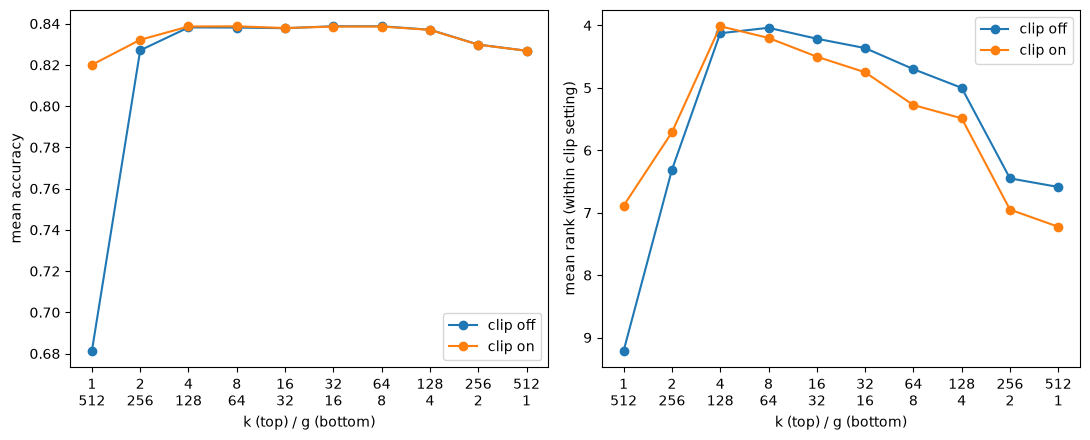

Seed variability of default (std over seeds per dataset):


,std_over_seeds
count,40.0000
mean,0.0064
std,0.0050
min,0.0000
25%,0.0025
50%,0.0051
75%,0.0096
max,0.0204


Paper claims next to our numbers (mechanical; no verdicts):


,paper_claim,our_best_k_by_rank,our_best_k_by_mean_acc,rank_of_k8,quantity,mean_delta_pp,W/D/L,p,n,n_variants_with_positive_mean_delta,k_with_largest_|clip_delta|,clip_delta_pp_by_k
0,k = 8 best (k x g = 512),8.0,32.0,4.0375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,max+min > max,NaN,NaN,NaN,default - max_soft,0.3880,21/5/14,0.1919,40.0,NaN,NaN,NaN
2,max+min > max,NaN,NaN,NaN,maxmin_soft - max_soft,0.3020,20/9/11,0.0254,40.0,NaN,NaN,NaN
3,soft+hard > either alone,NaN,NaN,NaN,maxmin_soft_and_hard - maxmin_soft,0.0918,18/4/18,0.8741,40.0,NaN,NaN,NaN
4,soft+hard > either alone,NaN,NaN,NaN,maxmin_soft_and_hard - maxmin_hard,0.8493,24/5/11,0.0214,40.0,NaN,NaN,NaN
5,soft+hard > either alone,NaN,NaN,NaN,"default (soft max, hard min) - maxmin_soft",0.0860,21/6/13,0.4024,40.0,NaN,NaN,NaN
6,soft+hard > either alone,NaN,NaN,NaN,"default (soft max, hard min) - maxmin_hard",0.8435,23/6/11,0.0101,40.0,NaN,NaN,NaN
7,diff always helps,NaN,NaN,NaN,default: diff on - off,0.0918,17/7/16,0.4035,40.0,7/7,NaN,NaN
8,clipping matters mainly at k = 1,NaN,NaN,NaN,k = 1: clip on - off,13.8712,34/2/4,0.0000,40.0,NaN,1.0,"{""1"": 13.871, ""2"": 0.51, ""4"": 0.046, ""8"": 0.06..."


mean delta diff on - off per variant (pp): {'default': np.float64(0.092), 'max_soft': np.float64(0.233), 'max_hard': np.float64(0.237), 'maxmin_soft': np.float64(0.08), 'maxmin_hard': np.float64(0.177), 'maxmin_soft_and_hard': np.float64(0.129), 'swapped': np.float64(0.103)}
alpha-at-edge rate by family: {'counting': 0.65, 'diff': 0.622, 'kg': 0.614}


In [24]:
# ---- A analysis (per-dataset means over seeds first) ----
def wdl_vs(ref_key, keys, table):
    """table: dataset x config accuracy (seed-averaged). Rows: each key vs ref_key, Holm across keys."""
    return pair_table([(f"{k} - {ref_key}", table[k], table[ref_key]) for k in keys if k != ref_key])

if csv_exists(PARTA_CSV):
    A = pd.read_csv(PARTA_CSV)
    for c in ["use_diff", "clip", "alpha_at_edge"]:
        A[c] = A[c].astype(str).str.lower().eq("true")
    print(f"Part A: {A['dataset'].nunique()} datasets, seeds per dataset: {sorted(A.groupby('dataset')['seed'].nunique().unique().tolist())}")
    seed_mean = A.groupby(["family", "variant", "k", "use_diff", "clip", "dataset"])["acc"].mean()

    # ---- counting x diff (paper Fig. 11), clip off ----
    cnt = seed_mean.loc["counting"].reset_index(); cnt = cnt[(cnt["k"] == 8) & (~cnt["clip"])]
    dif = seed_mean.loc["diff"].reset_index(); dif = dif[~dif["clip"]]
    cd = pd.concat([cnt.assign(cfg=cnt["variant"] + "|diff"), dif.assign(cfg=dif["variant"] + "|nodiff")])
    T_cd = cd.pivot(index="dataset", columns="cfg", values="acc").dropna()
    tab = pd.DataFrame({"mean_acc": T_cd.mean(), "mean_rank": T_cd.rank(axis=1, ascending=False).mean()}).sort_values("mean_rank")
    print(f"Counting x differencing (clip off), {len(T_cd)} datasets:"); display(tab.round(4))
    w_cd = wdl_vs("default|diff", list(T_cd.columns), T_cd)
    print("vs default|diff:"); display(w_cd.round(4))
    save_csv(tab.reset_index(names="config"), out("repro_partA_counting_diff.csv"))

    # ---- counting x clip (paper Fig. 12), diff on ----
    cc = cnt_all = seed_mean.loc["counting"].reset_index()
    cc = cc[(cc["k"] == 8) & (cc["variant"].isin(COUNTING_VARIANTS))]
    T_cc = cc.assign(cfg=cc["variant"] + np.where(cc["clip"], "|clip", "|noclip")).pivot(index="dataset", columns="cfg", values="acc").dropna()
    tab2 = pd.DataFrame({"mean_acc": T_cc.mean(), "mean_rank": T_cc.rank(axis=1, ascending=False).mean()}).sort_values("mean_rank")
    print(f"Counting x clipping (diff on), {len(T_cc)} datasets:"); display(tab2.round(4))
    w_cc = wdl_vs("default|noclip", list(T_cc.columns), T_cc)
    print("vs default|noclip:"); display(w_cc.round(4))
    save_csv(tab2.reset_index(names="config"), out("repro_partA_counting_clip.csv"))
    if "soft_only_mahak" in cnt_all["variant"].values:
        sm = cnt_all[cnt_all["variant"] == "soft_only_mahak"].set_index("dataset")["acc"]
        print("soft_only_mahak vs max_soft (clip off):")
        display(pair_table([("soft_only_mahak - max_soft", sm, T_cc["max_soft|noclip"])]).round(4))

    # ---- k/g (paper Fig. 10, k x g = 512) ----
    kg = seed_mean.loc["kg"].reset_index()
    T_kg = {clip: kg[kg["clip"] == clip].pivot(index="dataset", columns="k", values="acc").dropna() for clip in (False, True)}
    seed_sd = A[A["family"] == "kg"].groupby(["k", "clip", "dataset"])["acc"].std(ddof=1).groupby(["k", "clip"]).mean()
    kg_rows = []
    for clip, T in T_kg.items():
        rk = T.rank(axis=1, ascending=False).mean()
        w = wdl_vs(8, list(T.columns), T).set_index("comparison")
        for k in T.columns:
            row = {"clip": clip, "k": k, "g": 512 // k, "n": len(T), "mean_acc": T[k].mean(), "mean_rank_within_clip": rk[k],
                   "mean_seed_std": seed_sd.get((k, clip), np.nan)}
            key = f"{k} - 8"
            if key in w.index:
                row.update({"delta_vs_k8_pp": w.loc[key, "mean_delta_pp"], "W/D/L_vs_k8": w.loc[key, "W/D/L"], "p_holm_vs_k8": w.loc[key, "p_holm"]})
            kg_rows.append(row)
    kg_tab = pd.DataFrame(kg_rows)
    print("k/g sweep at k x g = 512:"); display(kg_tab.round(4))
    save_csv(kg_tab, out("repro_partA_kg.csv"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for clip, T in T_kg.items():
        axes[0].plot(range(len(T.columns)), T.mean().to_numpy(), marker="o", label=f"clip {'on' if clip else 'off'}")
        axes[1].plot(range(len(T.columns)), T.rank(axis=1, ascending=False).mean().to_numpy(), marker="o", label=f"clip {'on' if clip else 'off'}")
    for ax, yl in zip(axes, ["mean accuracy", "mean rank (within clip setting)"]):
        ax.set_xticks(range(len(KG_KS))); ax.set_xticklabels([f"{k}\n{512 // k}" for k in KG_KS]); ax.set_xlabel("k (top) / g (bottom)")
        ax.set_ylabel(yl); ax.legend()
    axes[1].invert_yaxis()
    plt.tight_layout(); plt.savefig(fig_path("repro_partA_kg"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()

    # ---- seed variability of 'default' ----
    dflt = A[(A["family"] == "counting") & (A["variant"] == "default") & (~A["clip"])]
    sv = dflt.groupby("dataset")["acc"].agg(["mean", "std", "min", "max"])
    print("Seed variability of default (std over seeds per dataset):"); display(sv["std"].describe().round(4).to_frame("std_over_seeds"))

    # ---- paper claims next to mechanically computed numbers (no verdicts) ----
    def pr(name, a, b_):
        both = pd.concat([a, b_], axis=1).dropna()
        r = compare(both.iloc[:, 0], both.iloc[:, 1])
        return {"quantity": name, "mean_delta_pp": r["mean_pp"], "W/D/L": f"{r['W']}/{r['D']}/{r['L']}", "p": r["p"], "n": r["n"]}
    T_noclip = T_kg[False]
    rk_off = T_noclip.rank(axis=1, ascending=False).mean()
    claims_rows = [
        {"paper_claim": "k = 8 best (k x g = 512)", "our_best_k_by_rank": int(rk_off.idxmin()), "our_best_k_by_mean_acc": int(T_noclip.mean().idxmax()),
         "rank_of_k8": float(rk_off[8])},
    ]
    claims_rows.append({"paper_claim": "max+min > max", **pr("default - max_soft", T_cc["default|noclip"], T_cc["max_soft|noclip"])})
    claims_rows.append({"paper_claim": "max+min > max", **pr("maxmin_soft - max_soft", T_cc["maxmin_soft|noclip"], T_cc["max_soft|noclip"])})
    claims_rows.append({"paper_claim": "soft+hard > either alone", **pr("maxmin_soft_and_hard - maxmin_soft", T_cc["maxmin_soft_and_hard|noclip"], T_cc["maxmin_soft|noclip"])})
    claims_rows.append({"paper_claim": "soft+hard > either alone", **pr("maxmin_soft_and_hard - maxmin_hard", T_cc["maxmin_soft_and_hard|noclip"], T_cc["maxmin_hard|noclip"])})
    claims_rows.append({"paper_claim": "soft+hard > either alone", **pr("default (soft max, hard min) - maxmin_soft", T_cc["default|noclip"], T_cc["maxmin_soft|noclip"])})
    claims_rows.append({"paper_claim": "soft+hard > either alone", **pr("default (soft max, hard min) - maxmin_hard", T_cc["default|noclip"], T_cc["maxmin_hard|noclip"])})
    d_on_off = {v: (T_cd[f"{v}|diff"] - T_cd[f"{v}|nodiff"]).mean() * 100 for v in COUNTING_VARIANTS}
    claims_rows.append({"paper_claim": "diff always helps", **pr("default: diff on - off", T_cd["default|diff"], T_cd["default|nodiff"]),
                        "n_variants_with_positive_mean_delta": f"{sum(x > 0 for x in d_on_off.values())}/{len(d_on_off)}"})
    clip_delta = {k: (T_kg[True][k] - T_kg[False][k]).mean() * 100 for k in KG_KS if k in T_kg[True].columns and k in T_kg[False].columns}
    claims_rows.append({"paper_claim": "clipping matters mainly at k = 1", **pr("k = 1: clip on - off", T_kg[True][1], T_kg[False][1]),
                        "k_with_largest_|clip_delta|": max(clip_delta, key=lambda k: abs(clip_delta[k])),
                        "clip_delta_pp_by_k": json.dumps({int(k): round(v, 3) for k, v in clip_delta.items()})})
    A_CLAIMS = pd.DataFrame(claims_rows)
    save_csv(A_CLAIMS, out("repro_partA_claims.csv"))
    print("Paper claims next to our numbers (mechanical; no verdicts):"); display(A_CLAIMS.round(4))
    print("mean delta diff on - off per variant (pp):", {k: round(v, 3) for k, v in d_on_off.items()})
    print("alpha-at-edge rate by family:", A.groupby("family")["alpha_at_edge"].mean().round(3).to_dict())

---
# Final summary (numbers only)

Maps the claim labels C1–C5 to the evidence each part produced, computed from the CSV files. A part that has not been run is listed as `not run`.

In [25]:
summary_rows = []
def add(claim, part, comparison, n=None, mean_delta_pp=None, wdl=None, p=None, p_kind=None, extra=None):
    summary_rows.append({"claim": claim, "part": part, "comparison": comparison, "n_datasets": n, "mean_delta_pp": mean_delta_pp,
                         "W/D/L": wdl, "p": p, "p_kind": p_kind, "extra": extra})

cfile = out("repro_partC_claims.csv")
if csv_exists(cfile):
    cl = pd.read_csv(cfile)
    for _, r in cl.iterrows():
        claim = "C1" if r["other"] in ("TDE", "MrSQM") else ("C2" if r["other"] in ("ROCKET", "InceptionTime", "TS-CHIEF", "HC2") else "C1/C2 context")
        add(claim, "C(a)", r["comparison"], r["n"], r["mean_delta_pp"], r["W/D/L"], r["p_holm"], "Holm (within Hydra source)",
            extra=f"paper W/D/L {r['paper_W/D/L']}" if isinstance(r["paper_W/D/L"], str) and r["paper_W/D/L"] else None)
else:
    add("C1/C2", "C", "not run")

bfile = out("repro_partB_pairs.csv")
if csv_exists(bfile):
    for _, r in pd.read_csv(bfile).iterrows():
        add("C3", "B", r["comparison"], r["n"], r["mean_delta_pp"], r["W/D/L"], r["p_holm"], "Holm (Part B pairs)")
else:
    add("C3", "B", "not run")
var_ = pd.read_csv(AUTHORS_VARIANTS_CSV).set_index("dataset")
add("C3", "authors' file", "Hydra+MultiRocket - Hydra (authors' 30-resample means)", len(var_),
    (var_["Hydra+MultiRocket"] - var_["Hydra"]).mean() * 100,
    f"{int((var_['Hydra+MultiRocket'] - var_['Hydra'] > DRAW_TOL).sum())}/{int(((var_['Hydra+MultiRocket'] - var_['Hydra']).abs() <= DRAW_TOL).sum())}/{int((var_['Hydra+MultiRocket'] - var_['Hydra'] < -DRAW_TOL).sum())}")

afile = out("repro_partA_claims.csv")
if csv_exists(afile):
    for _, r in pd.read_csv(afile).iterrows():
        if isinstance(r.get("quantity"), str):
            add("C4", "A", f"{r['paper_claim']}: {r['quantity']}", r["n"], r["mean_delta_pp"], r["W/D/L"], r["p"], "unadjusted")
        else:
            add("C4", "A", r["paper_claim"], extra=f"best k by rank {int(r['our_best_k_by_rank'])}, by mean acc {int(r['our_best_k_by_mean_acc'])}, rank of k=8 {r['rank_of_k8']:.2f}")
else:
    add("C4", "A", "not run")

dfile = out("repro_partD_summary.csv")
if csv_exists(dfile):
    ds_ = pd.read_csv(dfile)
    per = ds_[ds_["dataset"] != "MEAN over datasets"]
    add("C5", "D", "our 30-resample mean - paper (outliers)", len(per), per["ours_mean_minus_paper_pp"].mean(),
        extra=f"paper inside our 95% CI: {int(per['paper_in_ci95'].astype(str).str.lower().eq('true').sum())}/{len(per)}")
    add("C5", "D", "our resample 0 - paper (outliers)", len(per), per["ours_r0_minus_paper_pp"].mean())
    add("C5", "D", "default-split penalty: resample 0 - our 30-resample mean (outliers)", len(per), per["default_split_penalty_pp"].mean())
else:
    add("C5", "D", "not run")
rfile = out("repro_partC_ours_vs_published_r0.csv")
if csv_exists(rfile):
    rb = pd.read_csv(rfile)
    for _, r in rb[rb["other"].isin(["Hydra", "MultiROCKET-Hydra"])].iterrows():
        add("C5", "C(b)", r["comparison"], r["n"], r["mean_delta_pp"], r["W/D/L"], r["p_holm"], "Holm (Part C(b) table)")

SUMMARY = pd.DataFrame(summary_rows)
save_csv(SUMMARY, out("repro_claims_summary.csv"))
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(SUMMARY.round(4))
print("\nChecks logged in this session:")
for c in CHECKS:
    print("  PASS:", c)

,claim,part,comparison,n_datasets,mean_delta_pp,W/D/L,p,p_kind,extra
0,C2,C(a),Hydra (authors CSV) - HC2,112.0,-1.7955,33/10/69,0.0001,Holm (within Hydra source),paper W/D/L 27/5/80
1,C1,C(a),Hydra (authors CSV) - TDE,112.0,1.2558,69/6/37,0.0028,Holm (within Hydra source),paper W/D/L 73/2/37
2,C1,C(a),Hydra (authors CSV) - MrSQM,112.0,1.0729,72/7/33,0.0035,Holm (within Hydra source),paper W/D/L 69/1/42
3,C2,C(a),Hydra (authors CSV) - InceptionTime,112.0,-0.0857,54/6/52,1.0000,Holm (within Hydra source),NaN
4,C2,C(a),Hydra (authors CSV) - ROCKET,112.0,0.5194,63/6/43,0.3109,Holm (within Hydra source),paper W/D/L 56/3/53
5,C1/C2 context,C(a),Hydra (authors CSV) - MiniROCKET,112.0,-0.0955,61/8/43,0.8175,Holm (within Hydra source),NaN
6,C1/C2 context,C(a),Hydra (authors CSV) - MultiROCKET,112.0,-0.7982,44/10/58,0.0735,Holm (within Hydra source),NaN
7,C1/C2 context,C(a),Hydra (authors CSV) - DrCIF,112.0,0.9827,68/7/37,0.0285,Holm (within Hydra source),NaN
8,C2,C(a),Hydra (authors CSV) - TS-CHIEF,112.0,-0.4170,52/6/54,1.0000,Holm (within Hydra source),NaN
9,C1/C2 context,C(a),Hydra (authors CSV) - MultiROCKET-Hydra,112.0,-1.0532,34/13/65,0.0024,Holm (within Hydra source),NaN



Checks logged in this session:
  PASS: ECG200 seed 0 with the authors' grid = 0.8700 (Notebook 1: 0.8700)
  PASS: 18 outliers recomputed from Notebook 1 and the authors' CSV
  PASS: Part D resample 0 (seed 0) reproduces Notebook 1 exactly for 18 datasets
  PASS: Part B standalone Hydra (seed 0) equals Notebook 1 on all 112 datasets
  PASS: A1: HydraAllStats 'default' == official Hydra (torch.equal), ECG200 + Beef, seeds 0 and 1
  PASS: A2: HydraMaxOnly == max_soft; HydraCountingVariant hard/hard == maxmin_hard, soft/hard == default, soft/soft == soft_only_mahak (ECG200 + Beef, seeds 0 and 1)
  PASS: A3: at k = 1, hard_max_clip = number of positive outputs (PPV x T), soft_max_clip = sum of positive outputs; unclipped hard_max = T (constant)
  PASS: A4: 2-block variants have 2*k*g*n_dilations features for every k/g, with and without differencing
  PASS: A5: ECG200 seed 0 'default' via HydraAllStats = 0.8700 (Notebook 1: 0.8700)
